**Importing and Loading The Data**

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "5"

import numpy as np
import pandas as pd
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    accuracy_score,
    brier_score_loss,
    log_loss,
)

sns.set_theme(style="whitegrid")

# Load processed datasets directly from GitHub
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "brad-hof/Milestone2/main/data/processed"
)

CHECKPOINTS = ["pregame", "endq1", "endq2", "endq3"]
RANDOM_STATE = 42


The processed datasets are stored as CSV files, with separate files for each prediction checkpoint: pregame, end of the first quarter, halftime, and end of the third quarter. The following code loads each available dataset into a dictionary and reports its dimensions, allowing us to assess data availability before proceeding with the analysis.

In [4]:
data = {}

for checkpoint in CHECKPOINTS:
    url = f"{BASE_URL}/{checkpoint}.csv"

    try:
        data[checkpoint] = pd.read_csv(url)
        print(f"Loaded {checkpoint}: {data[checkpoint].shape}")

    except Exception as e:
        print(f"Failed to load {checkpoint}: {e}")

print(f"\nSuccessfully loaded {len(data)} of {len(CHECKPOINTS)} datasets.")

Loaded pregame: (1141, 24)
Loaded endq1: (1141, 42)
Loaded endq2: (1141, 42)
Loaded endq3: (1141, 42)

Successfully loaded 4 of 4 datasets.


**Initial Data Inspection**

The following code displays the first five rows of each dataset to examine its structure, column names, and sample values. It also reports the dimensions of each dataset to compare the number of observations and features available across prediction checkpoints.

In [6]:
for name, df in data.items():
    print(f"\nDataset: {name}")
    display(df.head())

for name, df in data.items():
    print(f"{name}: {df.shape}")


Dataset: pregame


,GAME_ID,GAME_DATE,HOME_WIN,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,...,ROLL_DREB,ROLL_REB,ROLL_AST,ROLL_STL,ROLL_BLK,ROLL_TOV,ROLL_PF,ROLL_PTS,ROLL_PLUS_MINUS,SPLIT
0,22500022,2025-10-31,0,0.645000,-5.6,-3.4,-0.05,2.8,11.6,-0.04,...,3.4,4.4,-5.2,0.8,0.8,1.4,-3.2,-5.2,7.4,train
1,22500024,2025-10-31,0,0.470297,-0.8,10.2,-0.06,4.0,10.8,0.01,...,1.2,0.6,2.2,0.0,1.6,-4.0,1.6,2.8,-3.0,train
2,22500142,2025-11-01,0,0.686567,3.0,-0.6,0.04,4.0,8.2,0.03,...,4.0,3.8,2.0,-2.2,0.8,1.0,3.2,10.8,12.6,train
3,22500144,2025-11-01,1,0.185930,-2.2,11.4,-0.08,-3.2,0.8,-0.08,...,2.6,8.0,-5.4,-4.0,0.8,-3.0,7.2,-6.8,-13.0,train
4,22500145,2025-11-01,0,0.235000,3.6,10.6,-0.02,5.6,9.2,0.07,...,7.0,4.2,4.4,0.0,0.0,-0.2,1.4,4.8,-4.4,train



Dataset: endq1


,GAME_ID,GAME_DATE,HOME_WIN,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,...,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF,SPLIT
0,22500022,2025-10-31,0,0.480000,-5.6,-3.4,-0.05,2.8,11.6,-0.04,...,4,-6,-2,-3,0,1,0,-4,-8.0,train
1,22500024,2025-10-31,0,0.385000,-0.8,10.2,-0.06,4.0,10.8,0.01,...,2,0,2,2,-2,0,1,1,-4.0,train
2,22500142,2025-11-01,0,0.810945,3.0,-0.6,0.04,4.0,8.2,0.03,...,-2,1,-1,4,1,0,-1,4,11.0,train
3,22500144,2025-11-01,1,0.183168,-2.2,11.4,-0.08,-3.2,0.8,-0.08,...,0,-3,-3,-2,0,-2,-1,-2,-4.0,train
4,22500145,2025-11-01,0,0.321608,3.6,10.6,-0.02,5.6,9.2,0.07,...,-1,-1,-2,1,-2,1,0,0,3.0,train



Dataset: endq2


,GAME_ID,GAME_DATE,HOME_WIN,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,...,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF,SPLIT
0,22500022,2025-10-31,0,0.555000,-5.6,-3.4,-0.05,2.8,11.6,-0.04,...,3,-4,-1,-1,-1,5,2,-2,-5.0,train
1,22500024,2025-10-31,0,0.775000,-0.8,10.2,-0.06,4.0,10.8,0.01,...,7,4,11,5,0,-1,-2,2,14.0,train
2,22500142,2025-11-01,0,0.675000,3.0,-0.6,0.04,4.0,8.2,0.03,...,1,0,1,-1,-1,2,-1,4,1.0,train
3,22500144,2025-11-01,1,0.184080,-2.2,11.4,-0.08,-3.2,0.8,-0.08,...,2,-1,1,-4,0,-2,-1,-7,-5.0,train
4,22500145,2025-11-01,0,0.034826,3.6,10.6,-0.02,5.6,9.2,0.07,...,1,-8,-7,-7,-3,-1,3,3,-19.0,train



Dataset: endq3


,GAME_ID,GAME_DATE,HOME_WIN,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,...,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF,SPLIT
0,22500022,2025-10-31,0,0.455000,-5.6,-3.4,-0.05,2.8,11.6,-0.04,...,2,-6,-4,-1,0,6,-1,-3,-4.0,train
1,22500024,2025-10-31,0,0.515000,-0.8,10.2,-0.06,4.0,10.8,0.01,...,7,-3,4,6,0,-2,-3,6,2.0,train
2,22500142,2025-11-01,0,0.351485,3.0,-0.6,0.04,4.0,8.2,0.03,...,1,1,2,-4,-2,2,3,4,-6.0,train
3,22500144,2025-11-01,1,0.155000,-2.2,11.4,-0.08,-3.2,0.8,-0.08,...,4,-1,3,-3,1,0,-2,-5,-6.0,train
4,22500145,2025-11-01,0,0.005000,3.6,10.6,-0.02,5.6,9.2,0.07,...,2,-16,-14,-8,-3,-1,1,6,-28.0,train


pregame: (1141, 24)
endq1: (1141, 42)
endq2: (1141, 42)
endq3: (1141, 42)


**Clustering Configuration**

This section initializes the parameters and storage objects required for the unsupervised learning analysis. We will evaluate K-means clustering across values of k from 2 -  8 and compare two feature variants: one that includes raw Kalshi probabilities and one that excludes them to examine whether clusters are driven primarily by favorite strength.

In [8]:
K_VALUES = range(2, 9)
RANDOM_STATE = 42

VARIANTS = ["with_probability", "without_probability"]

# Shared analysis objects, keyed by checkpoint and variant.
prepared = {}
validation_by_key = {}
best_k_by_key = {}
models = {}

# Results stored by checkpoint and variant.
hierarchical_by_key = {}
profile_by_key = {}
performance_by_key = {}

print("Configuration initialized.")
print("Checkpoints:", CHECKPOINTS)
print("Variants:", VARIANTS)

Configuration initialized.
Checkpoints: ['pregame', 'endq1', 'endq2', 'endq3']
Variants: ['with_probability', 'without_probability']


**1. Feature Preparation**

This section prepares the numerical features for clustering by removing identifier and outcome columns, excluding constant or entirely missing features, imputing missing values with the median, and standardizing the remaining variables. Two feature variants are created at each checkpoint: one includes Kalshi's home-win probability, while the other excludes it to examine whether clustering is primarily driven by the market's assessment of the favorite.

In [10]:
prepared = {}

excluded = {"GAME_ID", "GAME_DATE", "HOME_WIN", "SPLIT"}

for checkpoint in CHECKPOINTS:

    df = data[checkpoint].copy().reset_index(drop=True)

    features_all = [
        c for c in df.columns
        if c not in excluded
        and pd.api.types.is_numeric_dtype(df[c])
    ]

    features_all = [
        c for c in features_all
        if df[c].notna().any()
        and df[c].nunique(dropna=True) > 1
    ]

    if "KALSHI_PROB_HOME" not in features_all:
        raise ValueError(
            f"{checkpoint}: KALSHI_PROB_HOME is missing."
        )

    y = pd.to_numeric(df["HOME_WIN"], errors="coerce")

    probability = pd.to_numeric(
        df["KALSHI_PROB_HOME"], errors="coerce"
    )

    for variant in VARIANTS:

        include_prob = variant == "with_probability"

        features = features_all.copy()

        if not include_prob:
            features.remove("KALSHI_PROB_HOME")

        imputer = SimpleImputer(strategy="median")
        scaler = StandardScaler()

        X = scaler.fit_transform(
            imputer.fit_transform(df[features])
        )

        key = (checkpoint, variant)

        prepared[key] = {
            "df": df.copy(),
            "features": features,
            "X": X,
            "y": y.copy(),
            "probability": probability.copy(),
            "imputer": imputer,
            "scaler": scaler,
        }

        print(
            f"{checkpoint:8s} | {variant:18s} | "
            f"{len(features)} features | {X.shape[0]} rows"
        )

print(f"\nPrepared {len(prepared)} datasets.")

pregame  | with_probability   | 20 features | 1141 rows
pregame  | without_probability | 19 features | 1141 rows
endq1    | with_probability   | 38 features | 1141 rows
endq1    | without_probability | 37 features | 1141 rows
endq2    | with_probability   | 38 features | 1141 rows
endq2    | without_probability | 37 features | 1141 rows
endq3    | with_probability   | 38 features | 1141 rows
endq3    | without_probability | 37 features | 1141 rows

Prepared 8 datasets.


**Results**

The preprocessing step successfully prepared eight datasets, each containing 1,141 games. The pregame datasets contain 20 features with Kalshi probability and 19 without it, while each in-game checkpoint contains 38 and 37 features, respectively. This consistent number of observations supports comparisons across checkpoints, and the two feature variants will help determine whether cluster patterns reflect broader game characteristics or are dominated by raw market probabilities.

**2. K Means and Cluster Selection**

K-means clustering is evaluated for clusters using inertia, silhouette score, Calinski–Harabasz score, and Davies–Bouldin score. Elbow plots and silhouette scores are visualized for each prediction checkpoint and feature variant, with the candidate cluster count selected based on the highest silhouette score.


PREGAME | with_probability | Candidate k = 2


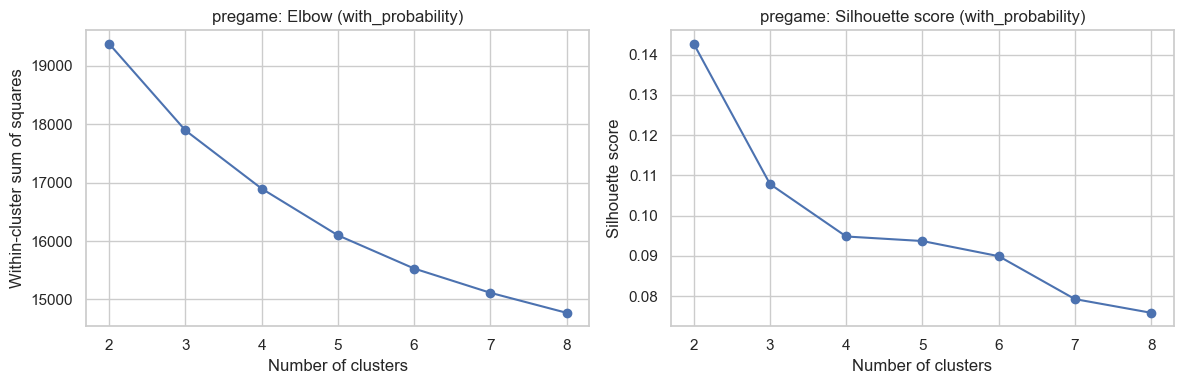


PREGAME | without_probability | Candidate k = 2


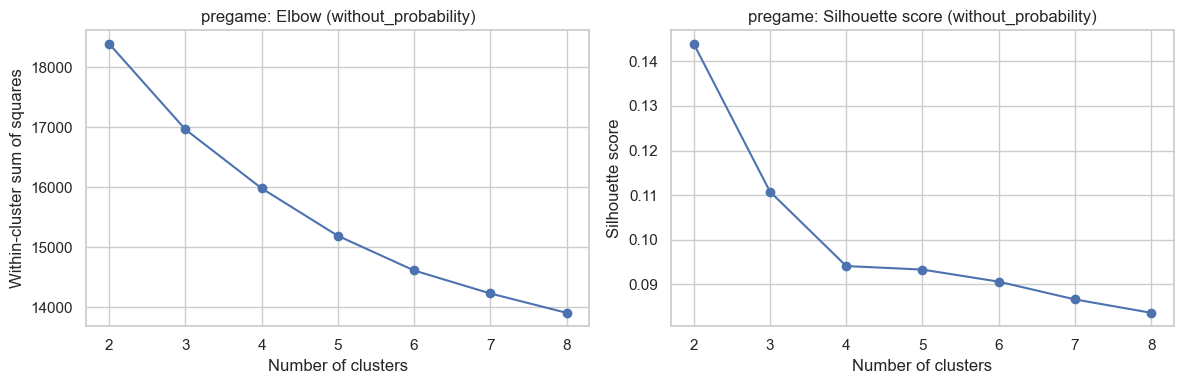


ENDQ1 | with_probability | Candidate k = 2


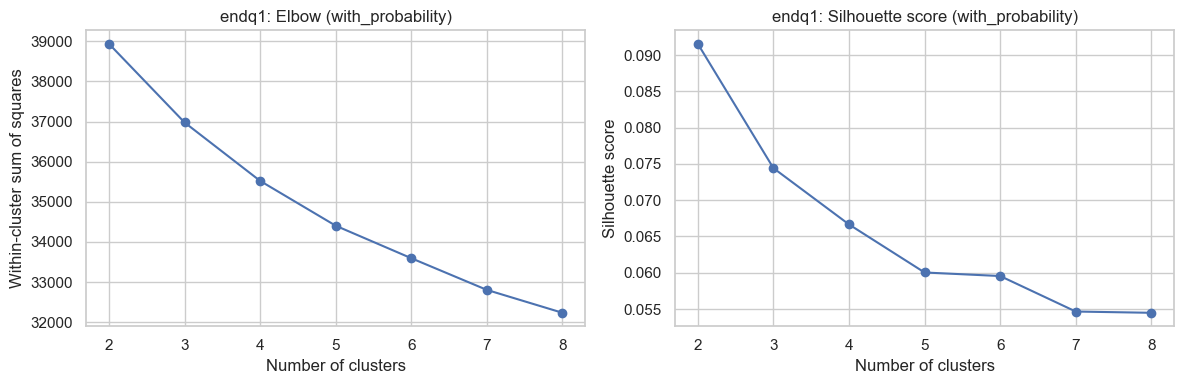


ENDQ1 | without_probability | Candidate k = 2


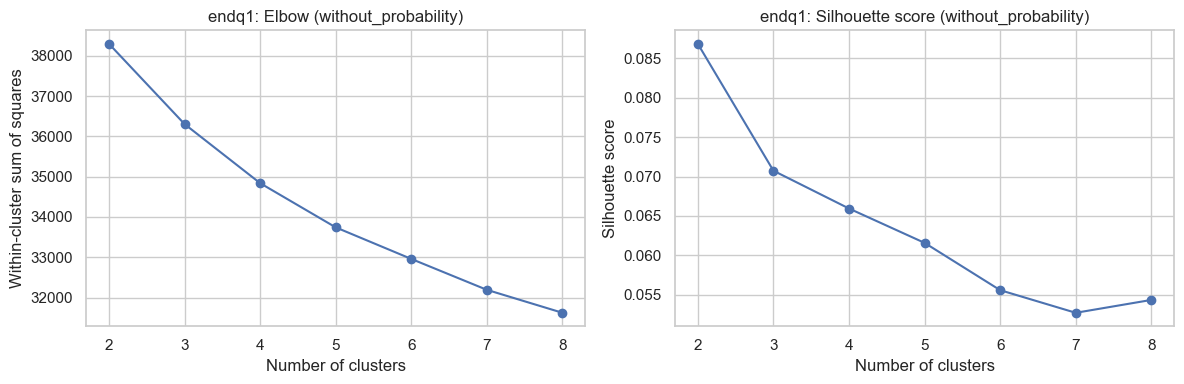


ENDQ2 | with_probability | Candidate k = 2


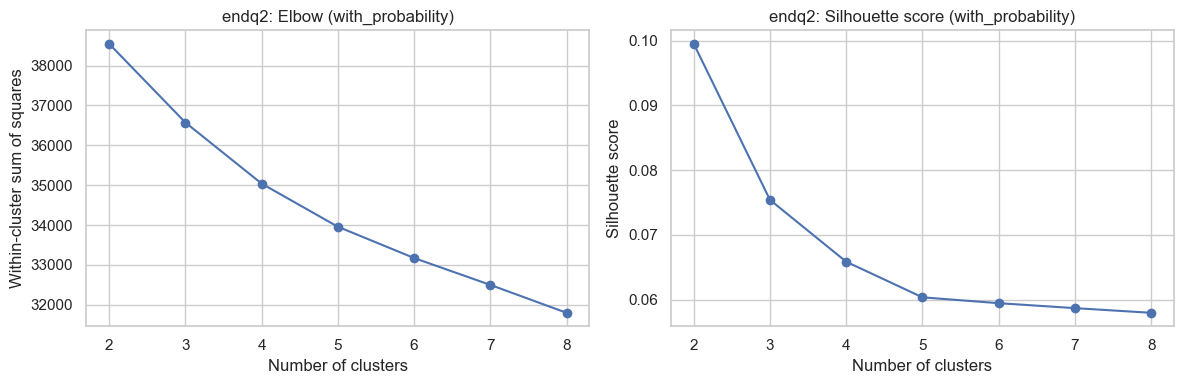


ENDQ2 | without_probability | Candidate k = 2


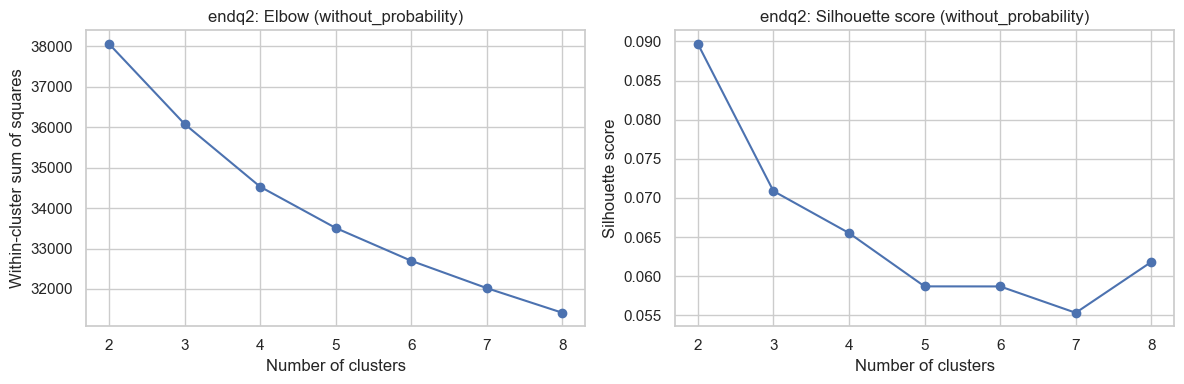


ENDQ3 | with_probability | Candidate k = 2


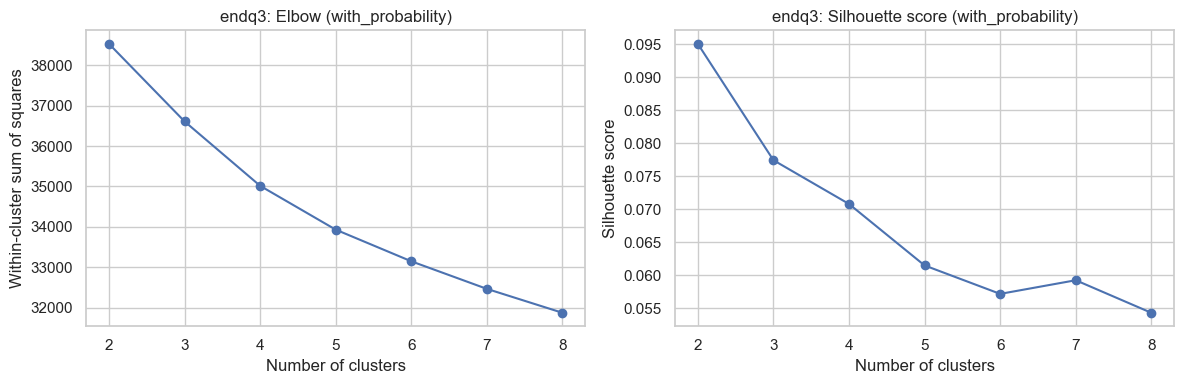


ENDQ3 | without_probability | Candidate k = 2


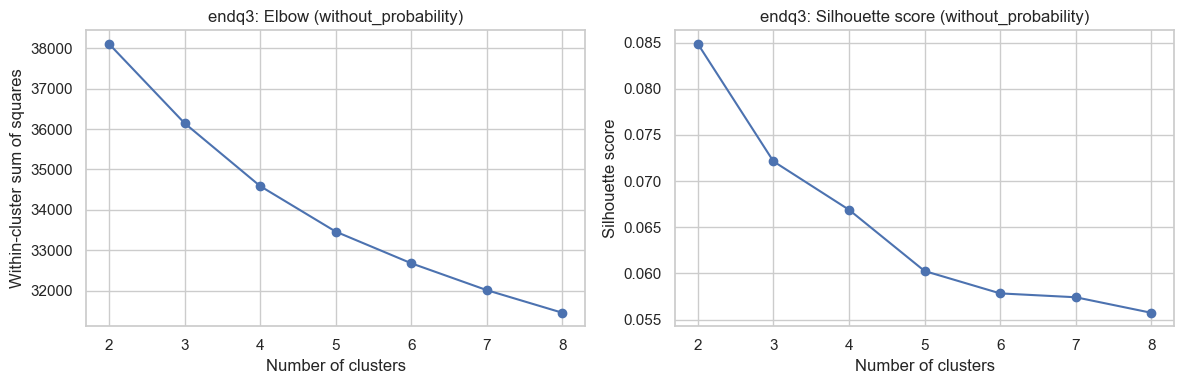


Completed K-means validation for all combinations.


In [13]:
validation_by_key = {}
best_k_by_key = {}

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)
        item = prepared[key]
        X = item["X"]

        scores = []

        for k in K_VALUES:

            km = KMeans(
                n_clusters=k,
                n_init=20,
                random_state=RANDOM_STATE
            )

            labels = km.fit_predict(X)

            scores.append({
                "checkpoint": checkpoint,
                "variant": variant,
                "k": k,
                "inertia": km.inertia_,
                "silhouette": silhouette_score(
                    X,
                    labels,
                    sample_size=min(500, len(X)),
                    random_state=RANDOM_STATE
                ),
                "calinski_harabasz": calinski_harabasz_score(
                    X, labels
                ),
                "davies_bouldin": davies_bouldin_score(
                    X, labels
                ),
                "smallest_cluster": int(
                    pd.Series(labels).value_counts().min()
                )
            })

        score_df = pd.DataFrame(scores)
        validation_by_key[key] = score_df

        best_k = int(
            score_df.loc[
                score_df["silhouette"].idxmax(), "k"
            ]
        )

        best_k_by_key[key] = best_k

        print(
            f"\n{checkpoint.upper()} | {variant} | "
            f"Candidate k = {best_k}"
        )

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        axes[0].plot(
            score_df["k"],
            score_df["inertia"],
            marker="o"
        )
        axes[0].set_title(
            f"{checkpoint}: Elbow ({variant})"
        )
        axes[0].set_xlabel("Number of clusters")
        axes[0].set_ylabel("Within-cluster sum of squares")

        axes[1].plot(
            score_df["k"],
            score_df["silhouette"],
            marker="o"
        )
        axes[1].set_title(
            f"{checkpoint}: Silhouette score ({variant})"
        )
        axes[1].set_xlabel("Number of clusters")
        axes[1].set_ylabel("Silhouette score")

        plt.tight_layout()
        plt.show()

print("\nCompleted K-means validation for all combinations.")

**Results**

Across all four prediction checkpoints and both feature variants, K=2 achieved the highest silhouette score and was selected as the candidate number of clusters. This suggests that a two-cluster solution provides the strongest separation according to this metric among the tested values.

**Final K Means Clustering**

Using the candidate cluster counts selected during validation, final K-means models are fitted for each prediction checkpoint and feature variant. Each game is assigned a cluster label, and the resulting cluster sizes are recorded to assess how the games are distributed between groups.

In [16]:
models = {}

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)
        item = prepared[key]

        X = item["X"]
        df = item["df"].copy()
        features = item["features"]
        best_k = best_k_by_key[key]

        kmeans = KMeans(
            n_clusters=best_k,
            n_init=20,
            random_state=RANDOM_STATE
        )

        clusters = kmeans.fit_predict(X)

        df[f"CLUSTER_{variant}"] = clusters

        print(
            f"\n{checkpoint.upper()} | {variant} | k={best_k}"
        )
        print("Cluster sizes:")
        print(
            pd.Series(clusters)
            .value_counts()
            .sort_index()
        )

        models[key] = {
            "features": features,
            "imputer": item["imputer"],
            "scaler": item["scaler"],
            "kmeans": kmeans,
            "best_k": best_k,
            "clusters": clusters,
            "data_with_clusters": df.copy(),
        }

print("\nFitted all final K-means models.")


PREGAME | with_probability | k=2
Cluster sizes:
0    548
1    593
Name: count, dtype: int64

PREGAME | without_probability | k=2
Cluster sizes:
0    548
1    593
Name: count, dtype: int64

ENDQ1 | with_probability | k=2
Cluster sizes:
0    565
1    576
Name: count, dtype: int64

ENDQ1 | without_probability | k=2
Cluster sizes:
0    564
1    577
Name: count, dtype: int64

ENDQ2 | with_probability | k=2
Cluster sizes:
0    548
1    593
Name: count, dtype: int64

ENDQ2 | without_probability | k=2
Cluster sizes:
0    592
1    549
Name: count, dtype: int64

ENDQ3 | with_probability | k=2
Cluster sizes:
0    547
1    594
Name: count, dtype: int64

ENDQ3 | without_probability | k=2
Cluster sizes:
0    549
1    592
Name: count, dtype: int64

Fitted all final K-means models.


**Results**

All eight K-means models were fitted successfully using two clusters per model. Across the 1,141 games, cluster sizes were relatively balanced, ranging from 547 to 594 games in the reported results.

**3. Hierarchical Clustering**

Hierarchical clustering is applied to each checkpoint and feature variant using Ward linkage and the same number of clusters selected for K-means. We compare the silhouette scores of both methods and use the Adjusted Rand Index (ARI) to measure how closely their cluster assignments agree.

In [19]:
hierarchical_by_key = {}

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)
        X = prepared[key]["X"]
        model_info = models[key]

        best_k = model_info["best_k"]
        clusters = model_info["clusters"]

        hierarchical = AgglomerativeClustering(
            n_clusters=best_k,
            linkage="ward"
        )

        hierarchical_labels = hierarchical.fit_predict(X)

        hierarchical_silhouette = silhouette_score(
            X,
            hierarchical_labels,
            sample_size=min(500, len(X)),
            random_state=RANDOM_STATE
        )

        ari = adjusted_rand_score(
            clusters,
            hierarchical_labels
        )

        kmeans_silhouette = float(
            validation_by_key[key].loc[
                validation_by_key[key]["k"] == best_k,
                "silhouette"
            ].iloc[0]
        )

        hierarchical_by_key[key] = {
            "checkpoint": checkpoint,
            "variant": variant,
            "k": best_k,
            "kmeans_silhouette": kmeans_silhouette,
            "hierarchical_silhouette": hierarchical_silhouette,
            "agreement_ARI": ari,
        }

        model_info["hierarchical"] = hierarchical
        model_info["hierarchical_labels"] = hierarchical_labels

        print(
            f"\n{checkpoint.upper()} | {variant}"
        )
        print(
            f"Hierarchical silhouette: "
            f"{hierarchical_silhouette:.3f}"
        )
        print(f"K-means vs. hierarchical ARI: {ari:.3f}")

print("\nCompleted hierarchical clustering comparisons.")


PREGAME | with_probability
Hierarchical silhouette: 0.119
K-means vs. hierarchical ARI: 0.200

PREGAME | without_probability
Hierarchical silhouette: 0.117
K-means vs. hierarchical ARI: 0.456

ENDQ1 | with_probability
Hierarchical silhouette: 0.056
K-means vs. hierarchical ARI: 0.214

ENDQ1 | without_probability
Hierarchical silhouette: 0.048
K-means vs. hierarchical ARI: 0.213

ENDQ2 | with_probability
Hierarchical silhouette: 0.073
K-means vs. hierarchical ARI: 0.373

ENDQ2 | without_probability
Hierarchical silhouette: 0.056
K-means vs. hierarchical ARI: 0.262

ENDQ3 | with_probability
Hierarchical silhouette: 0.073
K-means vs. hierarchical ARI: 0.495

ENDQ3 | without_probability
Hierarchical silhouette: 0.058
K-means vs. hierarchical ARI: 0.231

Completed hierarchical clustering comparisons.


**Results**

Hierarchical clustering produced relatively low silhouette scores across all configurations, ranging from 0.048 to 0.119, suggesting limited separation between clusters. Agreement with K-means varied, with ARI values ranging from 0.200 to 0.495; the strongest agreement occurred for the end-of-third-quarter model with probability included.

**4. PCA Cluster Visualization**

Principal Component Analysis (PCA) reduces the standardized feature space to two dimensions to visualize the K-means clusters for each checkpoint and feature variant. The proportion of variance explained by the first two principal components is reported to indicate how much of the original feature variation is represented in each visualization.

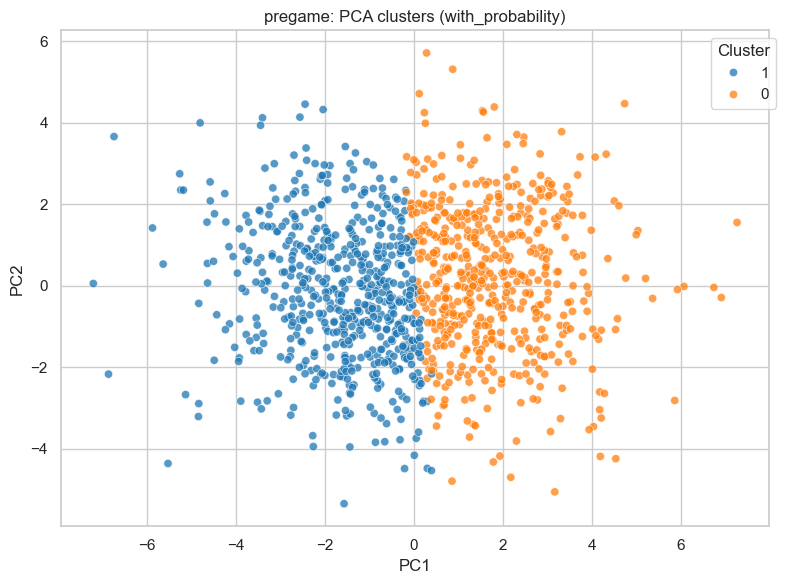

PREGAME | with_probability | Variance explained by first two PCs: 38.2%


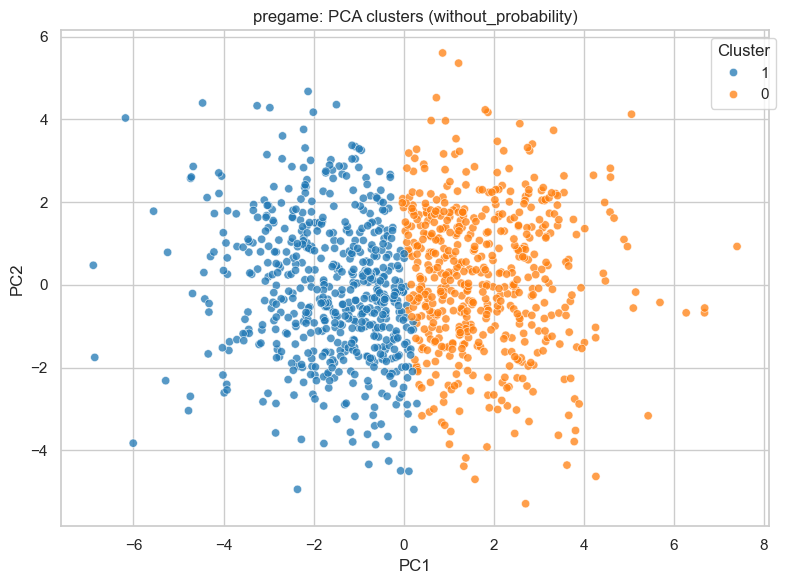

PREGAME | without_probability | Variance explained by first two PCs: 38.6%


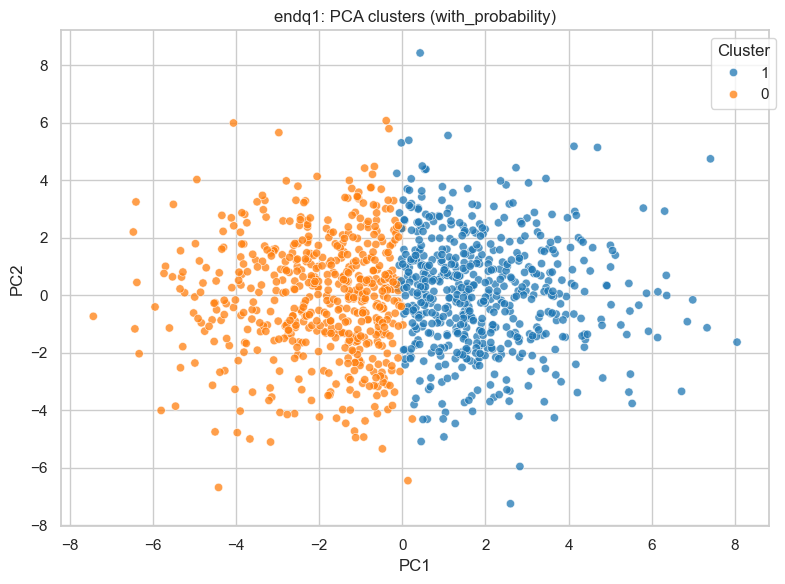

ENDQ1 | with_probability | Variance explained by first two PCs: 26.5%


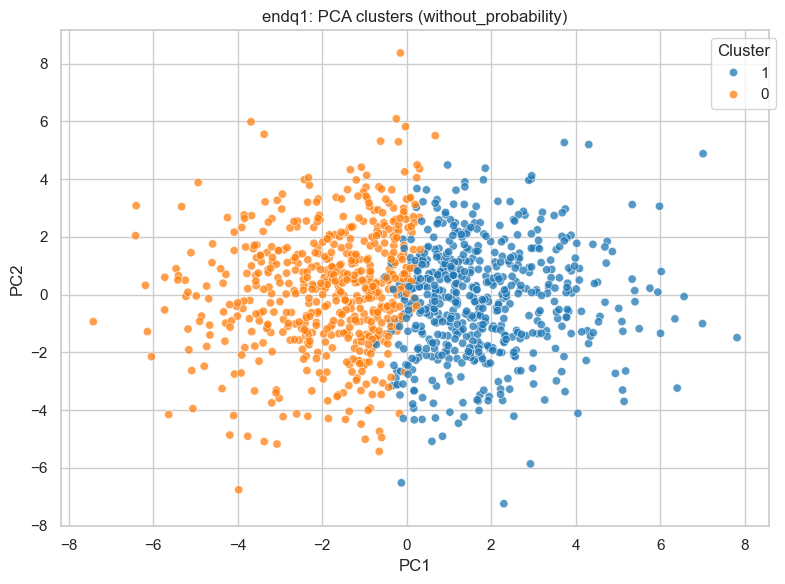

ENDQ1 | without_probability | Variance explained by first two PCs: 25.6%


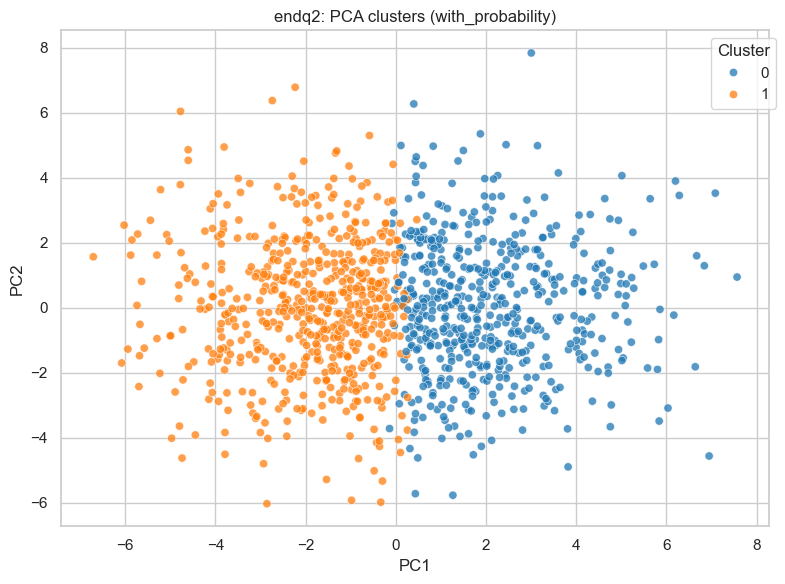

ENDQ2 | with_probability | Variance explained by first two PCs: 27.8%


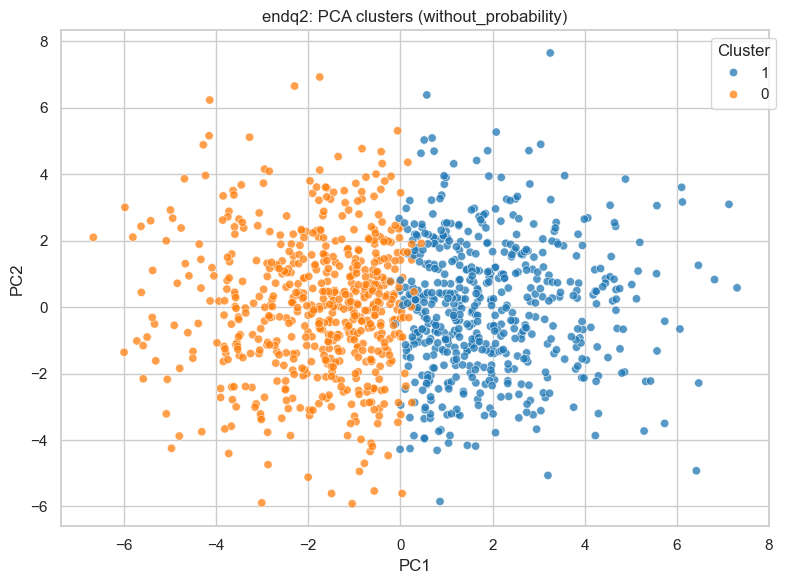

ENDQ2 | without_probability | Variance explained by first two PCs: 26.4%


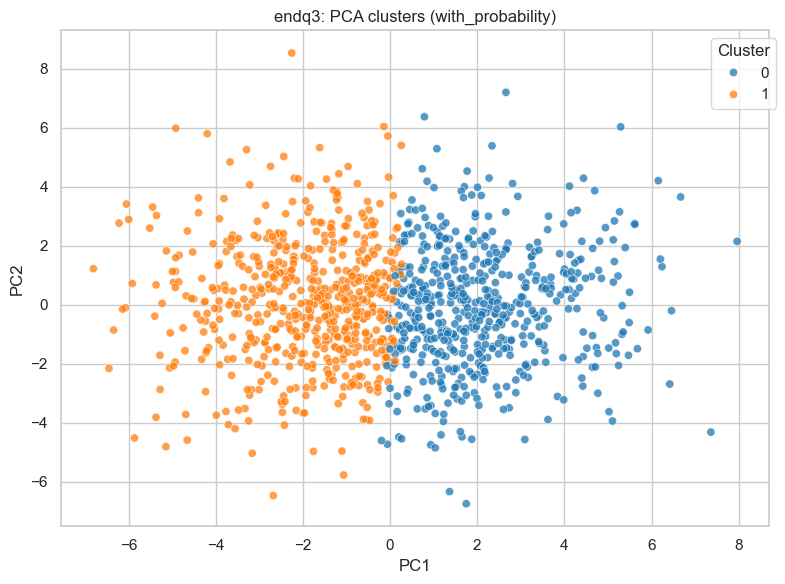

ENDQ3 | with_probability | Variance explained by first two PCs: 27.8%


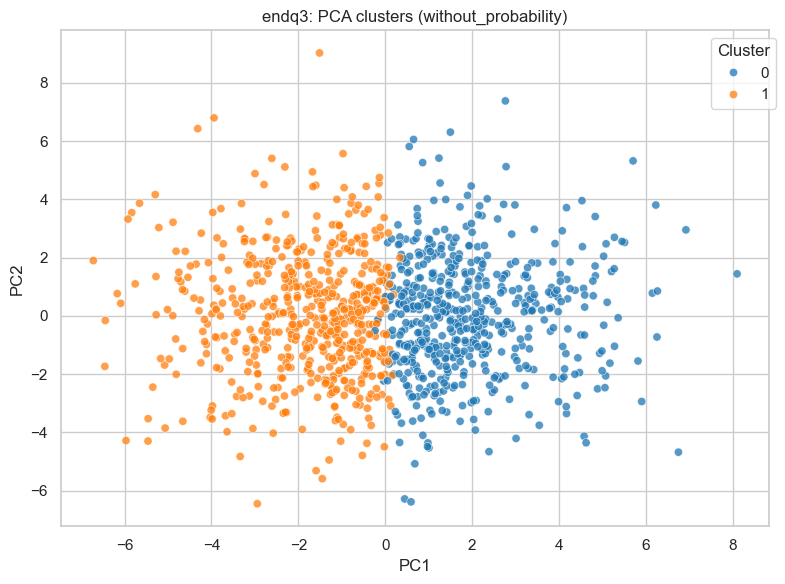

ENDQ3 | without_probability | Variance explained by first two PCs: 26.5%


In [22]:
for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)
        X = prepared[key]["X"]
        clusters = models[key]["clusters"]

        pca = PCA(n_components=2)
        components = pca.fit_transform(X)

        pca_df = pd.DataFrame({
            "PC1": components[:, 0],
            "PC2": components[:, 1],
            "Cluster": clusters.astype(str)
        })

        plt.figure(figsize=(8, 6))

        sns.scatterplot(
            data=pca_df,
            x="PC1",
            y="PC2",
            hue="Cluster",
            palette="tab10",
            alpha=0.75
        )

        plt.title(
            f"{checkpoint}: PCA clusters ({variant})"
        )
        plt.legend(
            title="Cluster",
            bbox_to_anchor=(1.02, 1)
        )
        plt.tight_layout()
        plt.show()

        models[key]["pca"] = pca

        print(
            f"{checkpoint.upper()} | {variant} | "
            "Variance explained by first two PCs: "
            f"{pca.explained_variance_ratio_.sum():.1%}"
        )

**Results**

The first two principal components explain 38.2%–38.6% of the variance in the pregame datasets and approximately 25.6%–27.8% in the in-game datasets. This indicates that the two-dimensional plots capture a larger proportion of the variation before tipoff than during the game.

**5. Cluster Profiles and Heatmaps**

This section summarizes the average feature values within each cluster and visualizes differences using heatmaps. Comparing team performance statistics, in-game scores, and Kalshi probabilities across clusters helps identify the characteristics that distinguish groups of NBA games at each prediction checkpoint.


PREGAME | with_probability
Average feature values by cluster:


,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,ROLL_OREB,ROLL_DREB,ROLL_REB,ROLL_AST,ROLL_STL,ROLL_BLK,ROLL_TOV,ROLL_PF,ROLL_PTS,ROLL_PLUS_MINUS
CLUSTER,,,,,,,,,,,,,,,,,,,,
0,0.651,2.690,1.542,0.022,1.523,1.578,0.026,-0.670,-0.945,0.004,0.078,1.642,1.72,2.415,0.135,0.032,-0.559,-0.367,6.233,8.693
1,0.457,-2.429,-1.446,-0.020,-1.610,-1.705,-0.027,0.555,0.788,-0.002,0.022,-1.532,-1.51,-2.302,0.119,-0.211,0.722,0.264,-5.914,-7.687


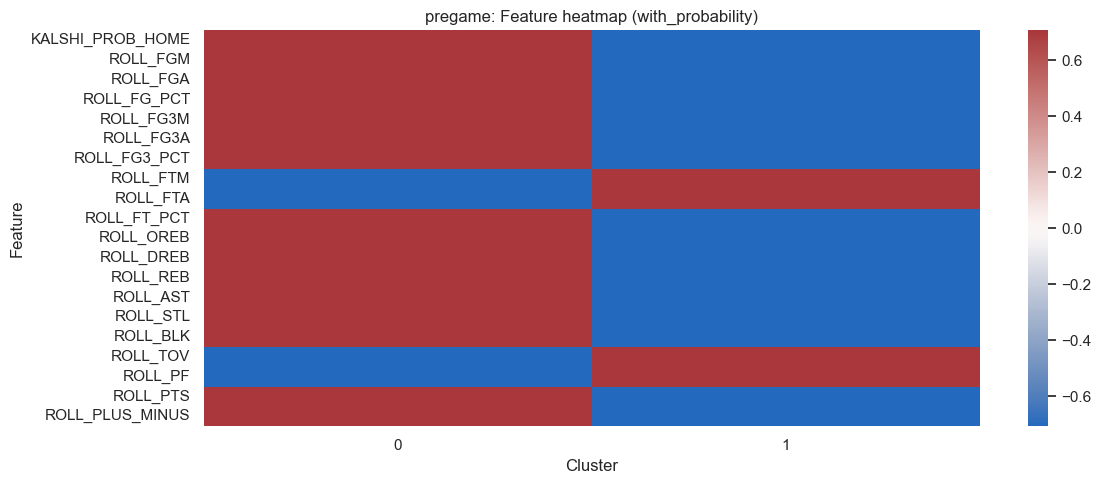


PREGAME | without_probability
Average feature values by cluster:


,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,ROLL_OREB,ROLL_DREB,ROLL_REB,ROLL_AST,ROLL_STL,ROLL_BLK,ROLL_TOV,ROLL_PF,ROLL_PTS,ROLL_PLUS_MINUS
CLUSTER,,,,,,,,,,,,,,,,,,,
0,2.747,1.593,0.022,1.543,1.505,0.027,-0.779,-1.119,0.005,0.009,1.550,1.558,2.497,0.103,-0.019,-0.623,-0.361,6.257,8.298
1,-2.482,-1.492,-0.020,-1.628,-1.637,-0.028,0.656,0.948,-0.003,0.086,-1.447,-1.361,-2.378,0.149,-0.164,0.781,0.259,-5.936,-7.322


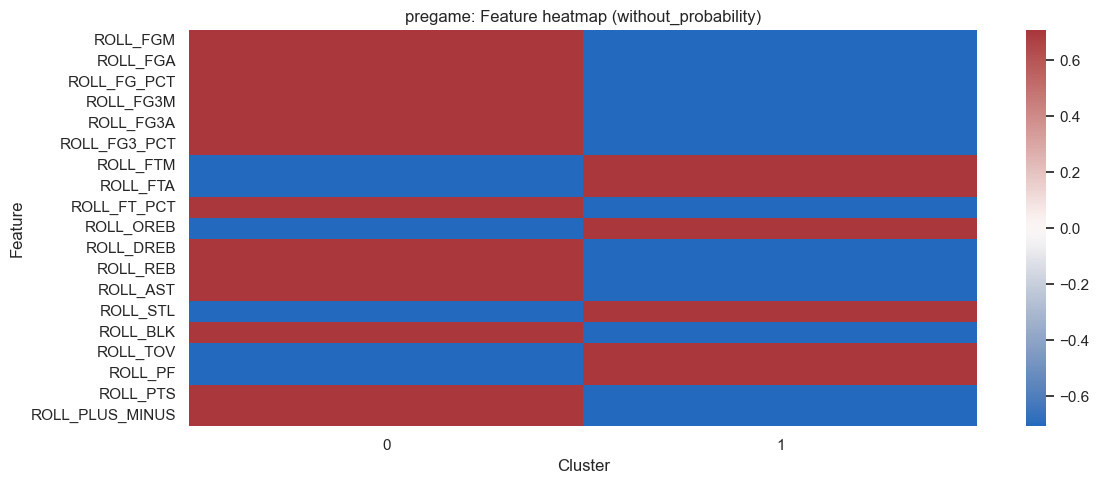


ENDQ1 | with_probability
Average feature values by cluster:


,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,...,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF
CLUSTER,,,,,,,,,,,,,,,,,,,,,
0,0.736,1.367,0.620,0.012,0.544,0.412,0.011,0.178,0.093,0.006,...,0.039,-0.060,1.878,1.818,1.982,0.372,0.375,-0.566,-0.405,6.865
1,0.368,-1.282,-0.629,-0.011,-0.742,-0.658,-0.014,-0.241,-0.180,-0.004,...,-0.019,-0.028,-1.651,-1.679,-1.627,-0.238,-0.262,0.380,0.106,-5.366


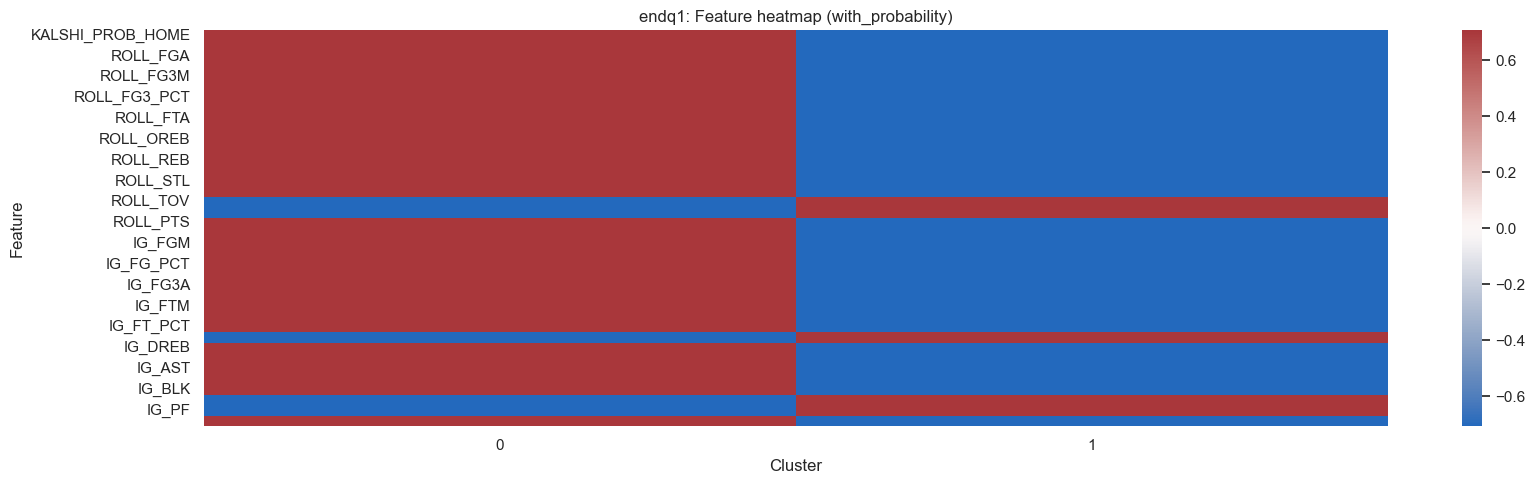


ENDQ1 | without_probability
Average feature values by cluster:


,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,ROLL_OREB,...,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF
CLUSTER,,,,,,,,,,,,,,,,,,,,,
0,1.843,1.008,0.015,0.971,0.913,0.017,-0.376,-0.566,0.004,0.131,...,0.03,-0.020,1.709,1.690,1.844,0.289,0.257,-0.429,-0.287,6.085
1,-1.743,-1.006,-0.014,-1.157,-1.146,-0.020,0.302,0.466,-0.002,-0.031,...,-0.01,-0.068,-1.480,-1.548,-1.485,-0.156,-0.146,0.244,-0.010,-4.582


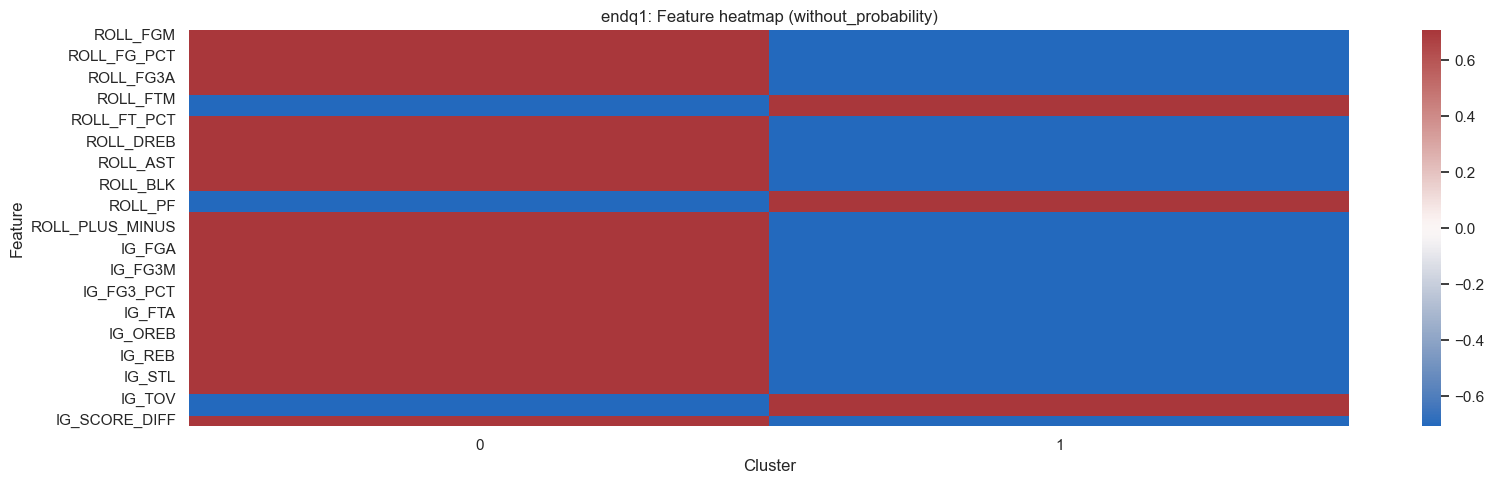


ENDQ2 | with_probability
Average feature values by cluster:


,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,...,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF
CLUSTER,,,,,,,,,,,,,,,,,,,,,
0,0.295,-1.208,-0.372,-0.012,-0.569,-0.167,-0.014,-0.502,-0.469,-0.005,...,-0.001,-0.400,-2.783,-3.182,-2.438,-0.651,-0.142,0.631,0.135,-8.602
1,0.775,1.173,0.323,0.012,0.323,-0.092,0.010,0.400,0.347,0.006,...,0.038,0.079,2.838,2.917,2.664,0.629,0.484,-0.771,-0.612,9.503


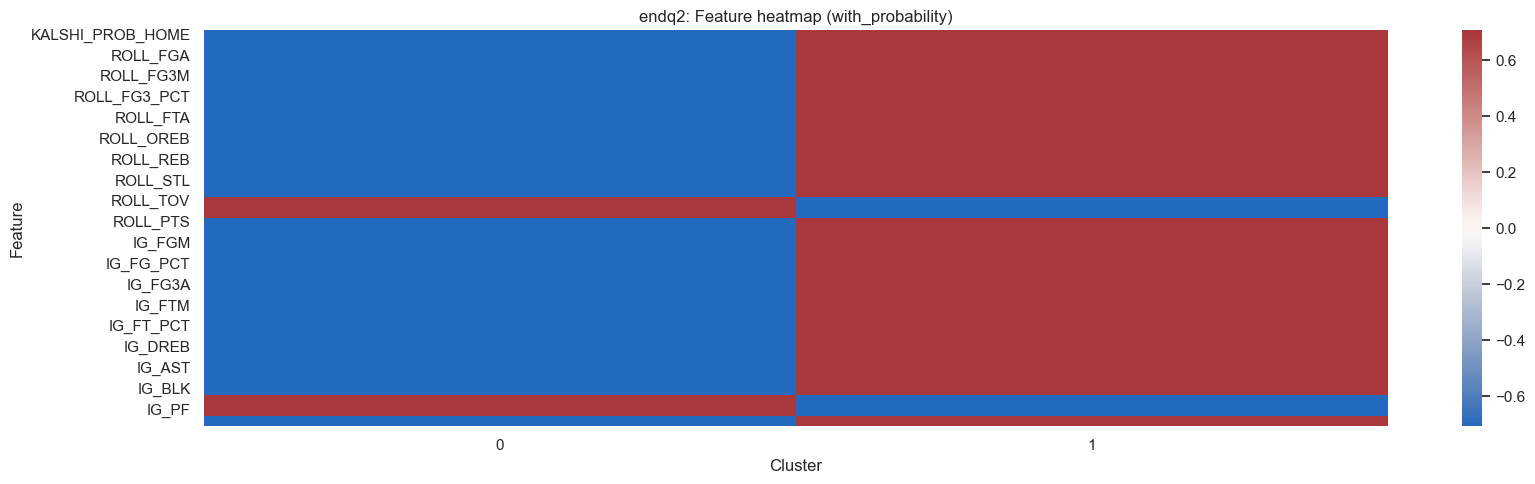


ENDQ2 | without_probability
Average feature values by cluster:


,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,ROLL_OREB,...,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF
CLUSTER,,,,,,,,,,,,,,,,,,,,,
0,1.317,0.430,0.013,0.435,0.028,0.011,0.236,0.151,0.006,0.213,...,0.040,0.020,2.840,2.860,2.650,0.586,0.486,-0.674,-0.561,9.270
1,-1.359,-0.486,-0.013,-0.688,-0.296,-0.016,-0.324,-0.255,-0.005,-0.128,...,-0.003,-0.335,-2.774,-3.109,-2.413,-0.603,-0.144,0.525,0.078,-8.319


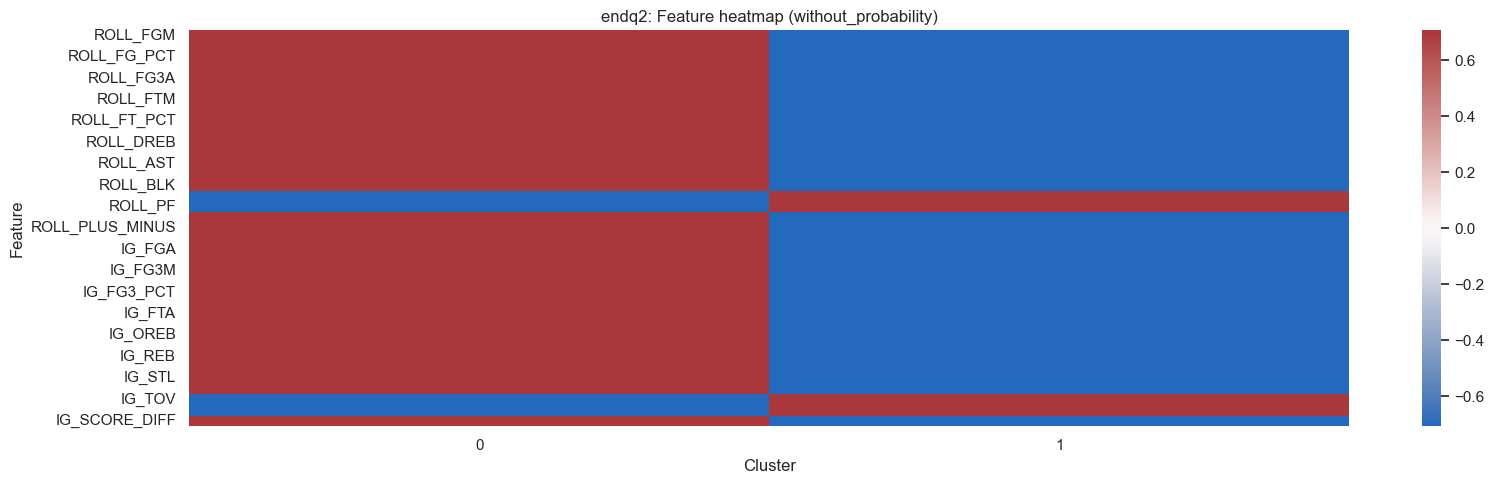


ENDQ3 | with_probability
Average feature values by cluster:


,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,...,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF
CLUSTER,,,,,,,,,,,,,,,,,,,,,
0,0.224,-1.026,-0.107,-0.011,-0.551,-0.079,-0.014,-0.288,-0.279,-0.003,...,-0.009,-0.834,-3.442,-4.276,-2.707,-0.729,-0.362,0.814,0.229,-10.442
1,0.838,1.001,0.078,0.011,0.305,-0.173,0.010,0.202,0.171,0.004,...,0.026,0.441,3.862,4.303,3.340,0.604,0.848,-0.875,-0.859,12.128


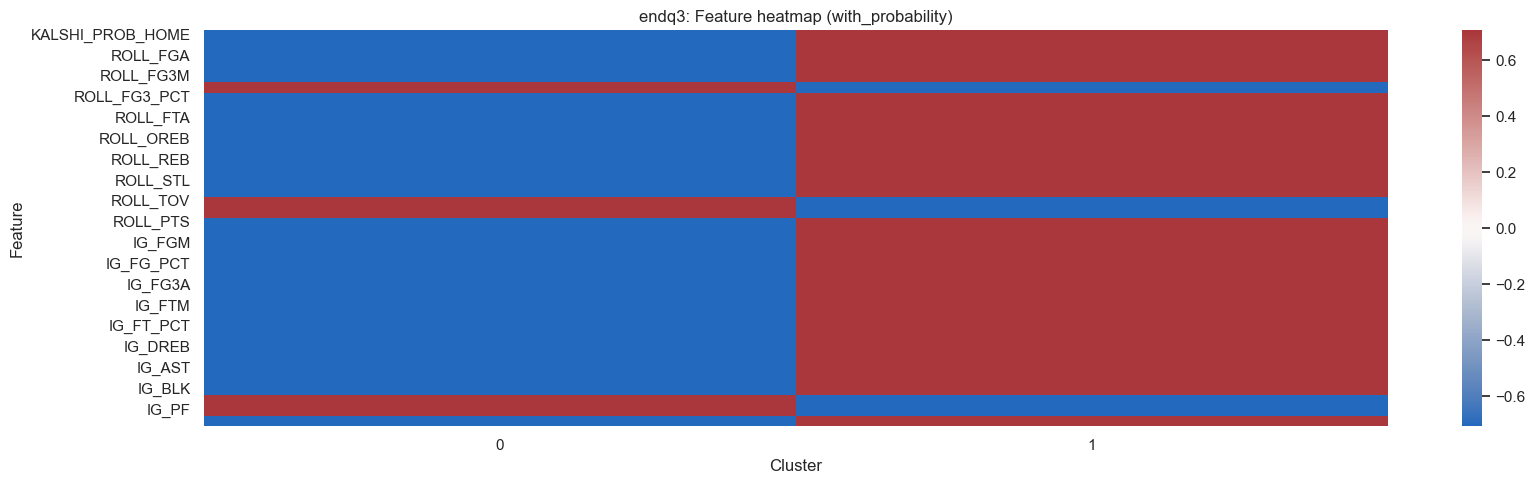


ENDQ3 | without_probability
Average feature values by cluster:


,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,ROLL_FT_PCT,ROLL_OREB,...,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF
CLUSTER,,,,,,,,,,,,,,,,,,,,,
0,-1.639,-0.491,-0.016,-0.894,-0.389,-0.021,-0.175,-0.146,-0.002,-0.149,...,-0.007,-0.787,-3.124,-3.911,-2.506,-0.537,-0.295,0.563,0.095,-9.082
1,1.576,0.435,0.015,0.626,0.114,0.016,0.098,0.049,0.003,0.232,...,0.024,0.402,3.591,3.993,3.174,0.431,0.791,-0.649,-0.738,10.943


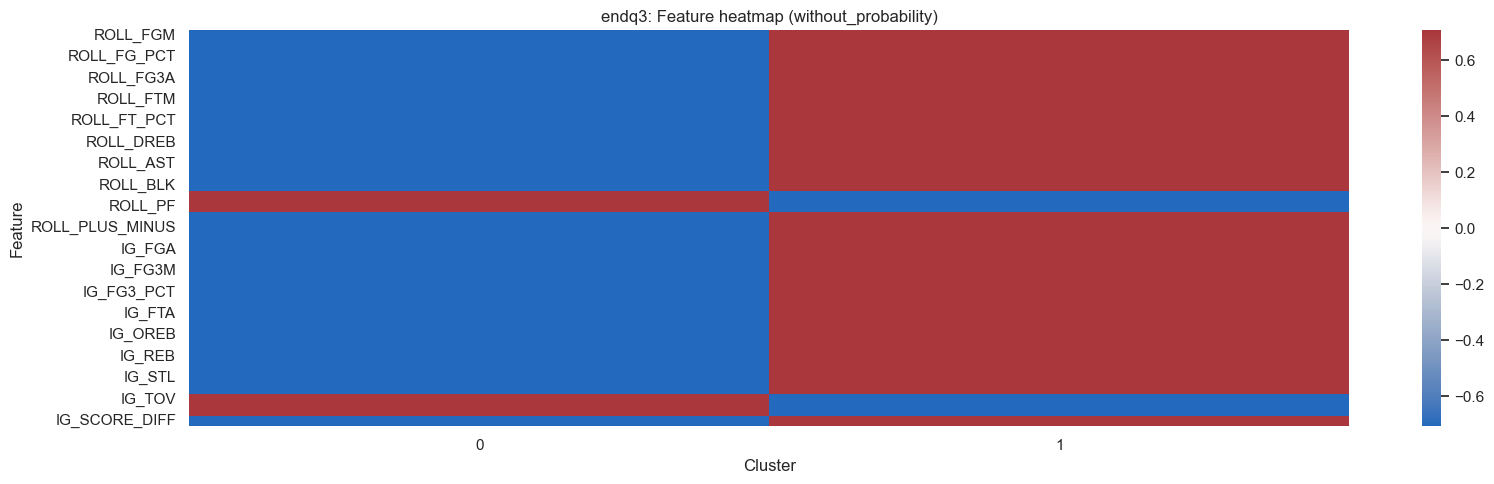


Completed all cluster profiles and heatmaps.


In [25]:
profile_by_key = {}

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)

        df = models[key]["data_with_clusters"]
        features = models[key]["features"]
        clusters = models[key]["clusters"]

        profile_data = df[features].copy()
        profile_data["CLUSTER"] = clusters

        profile = profile_data.groupby("CLUSTER")[features].mean()

        profile_by_key[key] = profile

        print(f"\n{checkpoint.upper()} | {variant}")
        print("Average feature values by cluster:")
        display(profile.round(3))

        models[key]["profile"] = profile

        # Standardize cluster means for visual comparison.
        heatmap_data = (
            profile - profile.mean(axis=0)
        ) / profile.std(axis=0).replace(0, 1)

        plt.figure(
            figsize=(max(12, len(features) * 0.45), 5)
        )

        sns.heatmap(
            heatmap_data.T,
            cmap="vlag",
            center=0
        )

        plt.title(
            f"{checkpoint}: Feature heatmap ({variant})"
        )
        plt.xlabel("Cluster")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

print("\nCompleted all cluster profiles and heatmaps.")

**Results**

The cluster profiles reveal differences in rolling team performance and in-game statistics, with several in-game clusters showing clear contrasts in score differential and Kalshi-implied home-win probability. For example, at the end of the third quarter, the probability-included clusters have average home-win probabilities of 0.224 and 0.838, alongside substantially different score differentials. 

**6. Kalshi Predictive Performance by Cluster**

This section evaluates Kalshi's predictive performance within each cluster using accuracy, Brier score, and log loss, while comparing mean predicted home-win probabilities with observed home-win rates. These metrics help assess whether market predictions differ in accuracy and calibration across groups of games at each checkpoint.

In [28]:
performance_by_key = {}

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)

        y = prepared[key]["y"]
        probability = prepared[key]["probability"]
        clusters = models[key]["clusters"]

        # Evaluate only valid binary outcomes and probabilities.
        eval_mask = (
            y.isin([0, 1])
            & probability.between(0, 1)
        )

        evaluation = pd.DataFrame({
            "HOME_WIN": y.loc[eval_mask].astype(int),
            "KALSHI_PROB": probability.loc[eval_mask].astype(float),
            "CLUSTER": clusters[eval_mask.to_numpy()]
        })

        rows = []

        for cluster_id, group in evaluation.groupby("CLUSTER"):

            actual = group["HOME_WIN"].to_numpy()
            p = group["KALSHI_PROB"].to_numpy()
            predicted = (p >= 0.5).astype(int)

            rows.append({
                "checkpoint": checkpoint,
                "variant": variant,
                "cluster": int(cluster_id),
                "n_games": len(group),
                "mean_kalshi_probability": p.mean(),
                "observed_home_win_rate": actual.mean(),
                "accuracy": accuracy_score(actual, predicted),
                "brier_score": brier_score_loss(actual, p),
                "log_loss": log_loss(
                    actual, p, labels=[0, 1]
                )
            })

        performance_by_key[key] = pd.DataFrame(rows)

        print(f"\n{checkpoint.upper()} | {variant}")
        display(performance_by_key[key].round(4))

print("\nCompleted Kalshi performance evaluation.")


PREGAME | with_probability


,checkpoint,variant,cluster,n_games,mean_kalshi_probability,observed_home_win_rate,accuracy,brier_score,log_loss
0,pregame,with_probability,0,548,0.6509,0.6551,0.7172,0.1851,0.5496
1,pregame,with_probability,1,593,0.4568,0.4570,0.6813,0.1990,0.5788



PREGAME | without_probability


,checkpoint,variant,cluster,n_games,mean_kalshi_probability,observed_home_win_rate,accuracy,brier_score,log_loss
0,pregame,without_probability,0,548,0.6314,0.6314,0.7208,0.1839,0.5474
1,pregame,without_probability,1,593,0.4748,0.4789,0.6779,0.2001,0.5808



ENDQ1 | with_probability


...


ENDQ3 | with_probability


,checkpoint,variant,cluster,n_games,mean_kalshi_probability,observed_home_win_rate,accuracy,brier_score,log_loss
0,endq3,with_probability,0,547,0.2238,0.2157,0.8099,0.1325,0.4031
1,endq3,with_probability,1,594,0.8380,0.8620,0.8586,0.0950,0.2982



ENDQ3 | without_probability


,checkpoint,variant,cluster,n_games,mean_kalshi_probability,observed_home_win_rate,accuracy,brier_score,log_loss
0,endq3,without_probability,0,549,0.2680,0.2678,0.8087,0.1324,0.4021
1,endq3,without_probability,1,592,0.7991,0.8159,0.8598,0.0950,0.2988



Completed Kalshi performance evaluation.


**Results**

Kalshi's predictive performance generally improves as games progress, with the highest accuracy occurring at the end of the third quarter, reaching approximately 86% in both clusters. At this checkpoint, Brier scores are approximately 0.095 and log loss is approximately 0.298, indicating stronger probabilistic predictions than before tipoff. Mean predicted probabilities are also relatively close to observed home-win rates across clusters.

**7. Consolidated Results Summary**

This section combines the clustering validation metrics, hierarchical clustering comparisons, Kalshi performance measures, and cluster feature profiles into consolidated tables. Bringing these results together makes it easier to compare clustering quality and prediction performance across checkpoints and feature variants.

In [31]:
validation_results = pd.concat(
    [
        validation_by_key[(checkpoint, variant)]
        for checkpoint in CHECKPOINTS
        for variant in VARIANTS
    ],
    ignore_index=True
)

hierarchical_results = pd.DataFrame(
    [
        hierarchical_by_key[(checkpoint, variant)]
        for checkpoint in CHECKPOINTS
        for variant in VARIANTS
    ]
)

performance_results = pd.concat(
    [
        performance_by_key[(checkpoint, variant)]
        for checkpoint in CHECKPOINTS
        for variant in VARIANTS
    ],
    ignore_index=True
)

profile_results = pd.concat(
    [
        profile_by_key[(checkpoint, variant)]
        .reset_index()
        .assign(
            checkpoint=checkpoint,
            variant=variant
        )
        for checkpoint in CHECKPOINTS
        for variant in VARIANTS
    ],
    ignore_index=True
)

print("\n1. K-MEANS VALIDATION")
display(
    validation_results.sort_values(
        ["checkpoint", "variant", "k"]
    ).round(4)
)

print("\n2. K-MEANS VS. HIERARCHICAL")
display(hierarchical_results.round(4))

print("\n3. KALSHI PERFORMANCE BY CLUSTER")
display(
    performance_results.sort_values(
        ["checkpoint", "variant", "cluster"]
    ).round(4)
)

print("\n4. CLUSTER FEATURE PROFILES")
display(profile_results.round(3))


1. K-MEANS VALIDATION


,checkpoint,variant,k,inertia,silhouette,calinski_harabasz,davies_bouldin,smallest_cluster
14,endq1,with_probability,2,38935.7112,0.0915,129.3668,2.9175,565
15,endq1,with_probability,3,36976.4223,0.0744,98.2009,2.9812,348
16,endq1,with_probability,4,35520.2059,0.0667,83.6291,2.8505,266
17,endq1,with_probability,5,34403.0668,0.0600,73.9237,2.6997,203
18,endq1,with_probability,6,33593.2476,0.0595,65.9835,2.7372,167
19,endq1,with_probability,7,32803.5424,0.0547,60.8103,2.7190,144
20,endq1,with_probability,8,32233.3049,0.0545,55.8618,2.7743,119
21,endq1,without_probability,2,38295.0414,0.0868,116.6499,3.0711,564
22,endq1,without_probability,3,36303.8855,0.0707,92.6777,2.9788,346
23,endq1,without_probability,4,34837.5653,0.0659,80.2813,2.8170,280



2. K-MEANS VS. HIERARCHICAL


,checkpoint,variant,k,kmeans_silhouette,hierarchical_silhouette,agreement_ARI
0,pregame,with_probability,2,0.1427,0.1192,0.1997
1,pregame,without_probability,2,0.1439,0.1172,0.4561
2,endq1,with_probability,2,0.0915,0.0555,0.2143
3,endq1,without_probability,2,0.0868,0.0485,0.2128
4,endq2,with_probability,2,0.0995,0.0731,0.3726
5,endq2,without_probability,2,0.0897,0.0559,0.2622
6,endq3,with_probability,2,0.0950,0.0734,0.4948
7,endq3,without_probability,2,0.0849,0.0575,0.2307



3. KALSHI PERFORMANCE BY CLUSTER


,checkpoint,variant,cluster,n_games,mean_kalshi_probability,observed_home_win_rate,accuracy,brier_score,log_loss
4,endq1,with_probability,0,565,0.7357,0.7416,0.7522,0.1668,0.4998
5,endq1,with_probability,1,576,0.3682,0.3663,0.7118,0.1915,0.5616
6,endq1,without_probability,0,564,0.7114,0.7181,0.7535,0.1663,0.4986
7,endq1,without_probability,1,577,0.3926,0.3899,0.7106,0.1919,0.5626
8,endq2,with_probability,0,548,0.2949,0.2974,0.7518,0.1637,0.4887
9,endq2,with_probability,1,593,0.7751,0.7875,0.8010,0.1348,0.4175
10,endq2,without_probability,0,592,0.7634,0.7804,0.8057,0.1317,0.4098
11,endq2,without_probability,1,549,0.3085,0.3060,0.7468,0.1670,0.4969
12,endq3,with_probability,0,547,0.2238,0.2157,0.8099,0.1325,0.4031
13,endq3,with_probability,1,594,0.8380,0.8620,0.8586,0.0950,0.2982



4. CLUSTER FEATURE PROFILES


,CLUSTER,KALSHI_PROB_HOME,ROLL_FGM,ROLL_FGA,ROLL_FG_PCT,ROLL_FG3M,ROLL_FG3A,ROLL_FG3_PCT,ROLL_FTM,ROLL_FTA,...,IG_FT_PCT,IG_OREB,IG_DREB,IG_REB,IG_AST,IG_STL,IG_BLK,IG_TOV,IG_PF,IG_SCORE_DIFF
0,0,0.651,2.690,1.542,0.022,1.523,1.578,0.026,-0.670,-0.945,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.457,-2.429,-1.446,-0.020,-1.610,-1.705,-0.027,0.555,0.788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,NaN,2.747,1.593,0.022,1.543,1.505,0.027,-0.779,-1.119,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,NaN,-2.482,-1.492,-0.020,-1.628,-1.637,-0.028,0.656,0.948,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,0.736,1.367,0.620,0.012,0.544,0.412,0.011,0.178,0.093,...,0.039,-0.060,1.878,1.818,1.982,0.372,0.375,-0.566,-0.405,6.865
5,1,0.368,-1.282,-0.629,-0.011,-0.742,-0.658,-0.014,-0.241,-0.180,...,-0.019,-0.028,-1.651,-1.679,-1.627,-0.238,-0.262,0.380,0.106,-5.366
6,0,NaN,1.843,1.008,0.015,0.971,0.913,0.017,-0.376,-0.566,...,0.030,-0.020,1.709,1.690,1.844,0.289,0.257,-0.429,-0.287,6.085
7,1,NaN,-1.743,-1.006,-0.014,-1.157,-1.146,-0.020,0.302,0.466,...,-0.010,-0.068,-1.480,-1.548,-1.485,-0.156,-0.146,0.244,-0.010,-4.582
8,0,0.295,-1.208,-0.372,-0.012,-0.569,-0.167,-0.014,-0.502,-0.469,...,-0.001,-0.400,-2.783,-3.182,-2.438,-0.651,-0.142,0.631,0.135,-8.602
9,1,0.775,1.173,0.323,0.012,0.323,-0.092,0.010,0.400,0.347,...,0.038,0.079,2.838,2.917,2.664,0.629,0.484,-0.771,-0.612,9.503


**Results**

The consolidated results show that the pregame datasets achieve the highest silhouette scores, while in-game clustering reveals groups with more distinct score differentials and market-implied probabilities. Kalshi's accuracy and probability metrics generally improve at later checkpoints, with end-of-third-quarter accuracy reaching approximately 86%.

**8. Cluster Quality Evaluation**

This section organizes the K-means validation metrics into a consolidated table to compare clustering quality across prediction checkpoints, feature variants, and candidate cluster counts. The metrics assess cluster separation, compactness, and size balance to help justify the selection of the final clustering solutions.

In [34]:
cluster_quality = validation_results.copy()

cluster_quality = cluster_quality.rename(columns={
    "k": "n_clusters",
    "inertia": "within_cluster_sum_squares",
    "silhouette": "silhouette_score",
    "calinski_harabasz": "calinski_harabasz_score",
    "davies_bouldin": "davies_bouldin_score",
    "smallest_cluster": "smallest_cluster_size"
})

quality_columns = [
    "checkpoint",
    "variant",
    "n_clusters",
    "within_cluster_sum_squares",
    "silhouette_score",
    "calinski_harabasz_score",
    "davies_bouldin_score",
    "smallest_cluster_size"
]

cluster_quality = cluster_quality[quality_columns].round(4)

print("CLUSTER QUALITY")
display(cluster_quality)

CLUSTER QUALITY


,checkpoint,variant,n_clusters,within_cluster_sum_squares,silhouette_score,calinski_harabasz_score,davies_bouldin_score,smallest_cluster_size
0,pregame,with_probability,2,19375.1677,0.1427,202.5099,2.3120,548
1,pregame,with_probability,3,17893.7065,0.1079,156.6507,2.3503,361
2,pregame,with_probability,4,16896.9766,0.0948,132.8537,2.2730,250
3,pregame,with_probability,5,16097.9362,0.0937,118.5907,2.2836,191
4,pregame,with_probability,6,15529.3335,0.0900,106.5713,2.3174,180
5,pregame,with_probability,7,15113.9727,0.0793,96.3638,2.3629,137
6,pregame,with_probability,8,14771.1955,0.0759,88.1957,2.3642,126
7,pregame,without_probability,2,18392.9255,0.1439,203.4934,2.3030,548
8,pregame,without_probability,3,16963.4943,0.1108,158.1704,2.3175,379
9,pregame,without_probability,4,15981.0986,0.0941,135.1287,2.2180,256


**Results**

The two-cluster solution achieves the highest silhouette score for every checkpoint and feature variant, with the strongest separation observed in the pregame data (approximately 0.143–0.144). In-game silhouette scores are lower, ranging from approximately 0.053 to 0.100, indicating weaker cluster separation as additional game statistics are incorporated.

**9. K Means Vs. Hierarchical Comparison**

This section compares K-means and hierarchical clustering using their silhouette scores and the Adjusted Rand Index (ARI). These metrics help assess which method produces better-separated clusters and how consistently the two algorithms group the same games.

In [37]:
algorithm_comparison = hierarchical_results.copy()

algorithm_comparison = algorithm_comparison.rename(columns={
    "k": "selected_cluster_count",
    "kmeans_silhouette": "kmeans_silhouette_score",
    "hierarchical_silhouette": "hierarchical_silhouette_score",
    "agreement_ARI": "adjusted_rand_index"
})

print("K-MEANS VS. HIERARCHICAL")
display(algorithm_comparison.round(4))

K-MEANS VS. HIERARCHICAL


,checkpoint,variant,selected_cluster_count,kmeans_silhouette_score,hierarchical_silhouette_score,adjusted_rand_index
0,pregame,with_probability,2,0.1427,0.1192,0.1997
1,pregame,without_probability,2,0.1439,0.1172,0.4561
2,endq1,with_probability,2,0.0915,0.0555,0.2143
3,endq1,without_probability,2,0.0868,0.0485,0.2128
4,endq2,with_probability,2,0.0995,0.0731,0.3726
5,endq2,without_probability,2,0.0897,0.0559,0.2622
6,endq3,with_probability,2,0.0950,0.0734,0.4948
7,endq3,without_probability,2,0.0849,0.0575,0.2307


**Results**

K-means achieves higher silhouette scores than hierarchical clustering across all eight configurations, indicating better-defined clusters according to this metric. ARI values range from 0.200 to 0.495, with the strongest agreement occurring in the end-of-third-quarter dataset that includes Kalshi probability. 

**10. Kalshi Performance**

This code evaluates Kalshi’s predictive performance within each cluster by calculating the calibration gap between predicted home-win probabilities and observed home-win rates. It then renames and organizes the relevant metrics, including accuracy, Brier score, and log loss, into a rounded summary table for comparison across checkpoints and clustering variants.

In [40]:
kalshi_evaluation = performance_results.copy()

kalshi_evaluation["calibration_gap"] = (
    kalshi_evaluation["observed_home_win_rate"]
    - kalshi_evaluation["mean_kalshi_probability"]
)

kalshi_evaluation["absolute_calibration_gap"] = (
    kalshi_evaluation["calibration_gap"].abs()
)

kalshi_evaluation = kalshi_evaluation.rename(columns={
    "cluster": "CLUSTER",
    "n_games": "evaluation_games",
    "mean_kalshi_probability": "mean_predicted_home_win_probability",
    "accuracy": "kalshi_accuracy"
})

evaluation_columns = [
    "checkpoint",
    "variant",
    "CLUSTER",
    "evaluation_games",
    "mean_predicted_home_win_probability",
    "observed_home_win_rate",
    "calibration_gap",
    "absolute_calibration_gap",
    "kalshi_accuracy",
    "brier_score",
    "log_loss"
]

kalshi_evaluation = kalshi_evaluation[
    evaluation_columns
].round(4)

print("KALSHI PERFORMANCE AND CALIBRATION")
display(kalshi_evaluation)

KALSHI PERFORMANCE AND CALIBRATION


,checkpoint,variant,CLUSTER,evaluation_games,mean_predicted_home_win_probability,observed_home_win_rate,calibration_gap,absolute_calibration_gap,kalshi_accuracy,brier_score,log_loss
0,pregame,with_probability,0,548,0.6509,0.6551,0.0042,0.0042,0.7172,0.1851,0.5496
1,pregame,with_probability,1,593,0.4568,0.4570,0.0002,0.0002,0.6813,0.1990,0.5788
2,pregame,without_probability,0,548,0.6314,0.6314,-0.0001,0.0001,0.7208,0.1839,0.5474
3,pregame,without_probability,1,593,0.4748,0.4789,0.0041,0.0041,0.6779,0.2001,0.5808
4,endq1,with_probability,0,565,0.7357,0.7416,0.0059,0.0059,0.7522,0.1668,0.4998
5,endq1,with_probability,1,576,0.3682,0.3663,-0.0019,0.0019,0.7118,0.1915,0.5616
6,endq1,without_probability,0,564,0.7114,0.7181,0.0067,0.0067,0.7535,0.1663,0.4986
7,endq1,without_probability,1,577,0.3926,0.3899,-0.0026,0.0026,0.7106,0.1919,0.5626
8,endq2,with_probability,0,548,0.2949,0.2974,0.0025,0.0025,0.7518,0.1637,0.4887
9,endq2,with_probability,1,593,0.7751,0.7875,0.0124,0.0124,0.8010,0.1348,0.4175


**Results**

Kalshi probabilities are generally well-calibrated across clusters, with small differences between predicted home-win probabilities and observed win rates. Predictive accuracy improves as games progress, while including Kalshi probabilities in the clustering features provides no consistent performance advantage over using basketball statistics alone.

**11. Overall Checkpoint Comparison**

This code calculates game-count-weighted performance metrics for each checkpoint and clustering variant, combining cluster-level results into an overall summary. It compares accuracy, Brier score, log loss, and absolute calibration gap from pregame through the end of the third quarter to assess how Kalshi’s predictive performance changes as games progress.



In [43]:
def weighted_average(
    group,
    column,
    weight_column="evaluation_games"
):
    valid = (
        group[column].notna()
        & group[weight_column].notna()
    )

    if not valid.any():
        return np.nan

    return np.average(
        group.loc[valid, column],
        weights=group.loc[valid, weight_column]
    )


checkpoint_summary_rows = []

for (checkpoint, variant), group in kalshi_evaluation.groupby(
    ["checkpoint", "variant"]
):

    checkpoint_summary_rows.append({
        "checkpoint": checkpoint,
        "variant": variant,
        "total_evaluated_games": group["evaluation_games"].sum(),
        "weighted_accuracy": weighted_average(
            group, "kalshi_accuracy"
        ),
        "weighted_brier_score": weighted_average(
            group, "brier_score"
        ),
        "weighted_log_loss": weighted_average(
            group, "log_loss"
        ),
        "weighted_absolute_calibration_gap": weighted_average(
            group, "absolute_calibration_gap"
        )
    })

checkpoint_summary = pd.DataFrame(checkpoint_summary_rows)

checkpoint_order = {
    "pregame": 0,
    "endq1": 1,
    "endq2": 2,
    "endq3": 3
}

checkpoint_summary["_order"] = checkpoint_summary[
    "checkpoint"
].map(checkpoint_order)

checkpoint_summary = (
    checkpoint_summary
    .sort_values(["_order", "variant"])
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("OVERALL CHECKPOINT COMPARISON")
display(checkpoint_summary.round(4))

OVERALL CHECKPOINT COMPARISON


,checkpoint,variant,total_evaluated_games,weighted_accuracy,weighted_brier_score,weighted_log_loss,weighted_absolute_calibration_gap
0,pregame,with_probability,1141,0.6985,0.1923,0.5648,0.0021
1,pregame,without_probability,1141,0.6985,0.1923,0.5648,0.0022
2,endq1,with_probability,1141,0.7318,0.1793,0.5310,0.0039
3,endq1,without_probability,1141,0.7318,0.1792,0.5310,0.0046
4,endq2,with_probability,1141,0.7774,0.1487,0.4517,0.0076
5,endq2,without_probability,1141,0.7774,0.1487,0.4517,0.0100
6,endq3,with_probability,1141,0.8353,0.1130,0.3485,0.0163
7,endq3,without_probability,1141,0.8352,0.1130,0.3485,0.0089


**Results**

Kalshi's predictive performance improves steadily as games progress, with weighted accuracy increasing form 69.9% pregame to 83.5% by the end of the third quarter. Both clustering variants produce nearly identical accuracy and probability scores.

**12: Pregame Probabilities**

This cell groups games into three categories based on the absolute difference between the pregame Kalshi home-win probability and 0.50: closely matched games, moderate favorites, and clear favorites. It then evaluates Kalshi’s accuracy, Brier score, log loss, and calibration gap for each group at every checkpoint to assess whether predictive performance varies with pregame favorite strength.

In [46]:
favorite_results = []

# Use pregame probabilities to define game types.
pregame_item = prepared[("pregame", "with_probability")]
pregame_prob = pregame_item["probability"].reset_index(drop=True)

# Distance from 0.50 measures how strongly the market favors
# either the home or away team.
favorite_strength = (pregame_prob - 0.50).abs()

favorite_group = pd.cut(
    favorite_strength,
    bins=[-np.inf, 0.10, 0.25, np.inf],
    labels=[
        "Closely matched",
        "Moderate favorite",
        "Clear favorite"
    ],
    right=False
)

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)

        y = prepared[key]["y"].reset_index(drop=True)
        p = prepared[key]["probability"].reset_index(drop=True)

        # Assumes observations are aligned across checkpoints.
        if not (len(y) == len(p) == len(favorite_group)):
            raise ValueError(
                f"Row alignment issue for {key}. "
                "Match games using a unique game ID before comparing."
            )

        evaluation = pd.DataFrame({
            "HOME_WIN": y,
            "PROBABILITY": p,
            "FAVORITE_GROUP": favorite_group
        })

        evaluation = evaluation.loc[
            evaluation["HOME_WIN"].isin([0, 1])
            & evaluation["PROBABILITY"].between(0, 1)
            & evaluation["FAVORITE_GROUP"].notna()
        ].copy()

        evaluation["HOME_WIN"] = evaluation["HOME_WIN"].astype(int)

        for group_name, group in evaluation.groupby(
            "FAVORITE_GROUP", observed=True
        ):
            actual = group["HOME_WIN"].to_numpy()
            prob = group["PROBABILITY"].to_numpy()

            favorite_results.append({
                "checkpoint": checkpoint,
                "variant": variant,
                "favorite_group": str(group_name),
                "n_games": len(group),
                "accuracy": accuracy_score(
                    actual, (prob >= 0.5).astype(int)
                ),
                "brier_score": brier_score_loss(actual, prob),
                "log_loss": log_loss(
                    actual, prob, labels=[0, 1]
                ),
                "predicted_home_win_rate": prob.mean(),
                "observed_home_win_rate": actual.mean(),
                "calibration_gap": actual.mean() - prob.mean()
            })

favorite_results = pd.DataFrame(favorite_results)

print("PERFORMANCE BY PREGAME FAVORITE STRENGTH")
display(
    favorite_results.round(4).sort_values(
        ["checkpoint", "variant", "favorite_group"]
    )
)

PERFORMANCE BY PREGAME FAVORITE STRENGTH


,checkpoint,variant,favorite_group,n_games,accuracy,brier_score,log_loss,predicted_home_win_rate,observed_home_win_rate,calibration_gap
8,endq1,with_probability,Clear favorite,410,0.8073,0.1446,0.4461,0.5930,0.5854,-0.0077
6,endq1,with_probability,Closely matched,309,0.6731,0.2036,0.5886,0.5182,0.5049,-0.0134
7,endq1,with_probability,Moderate favorite,422,0.7014,0.1951,0.5712,0.5319,0.5545,0.0226
11,endq1,without_probability,Clear favorite,410,0.8073,0.1446,0.4461,0.5930,0.5854,-0.0077
9,endq1,without_probability,Closely matched,309,0.6731,0.2036,0.5886,0.5182,0.5049,-0.0134
10,endq1,without_probability,Moderate favorite,422,0.7014,0.1951,0.5712,0.5319,0.5545,0.0226
14,endq2,with_probability,Clear favorite,410,0.8366,0.1197,0.3791,0.5798,0.5854,0.0055
12,endq2,with_probability,Closely matched,309,0.7476,0.1648,0.4918,0.5248,0.5049,-0.0199
13,endq2,with_probability,Moderate favorite,422,0.7417,0.1651,0.4930,0.5246,0.5545,0.0299
17,endq2,without_probability,Clear favorite,410,0.8366,0.1197,0.3791,0.5798,0.5854,0.0055


**Results**

Kalshi performs best in games with clear pregame favorites, achieving 83.66% accuracy before the game and 88.05% by the end of the third quarter, compared with 53.40% and 83.17%, respectively, for closely matched games. Accuracy improves across all groups as the game progresses, although the moderate-favorite group generally shows positive calibration gaps, suggesting Kalshi tends to underestimate home-win rates in these games.

**Visualizations**

These visualizations compare Kalshi’s accuracy, Brier score, and calibration gap across pregame favorite-strength categories at each game checkpoint. They help identify which types of games Kalshi predicts most reliably, how probability forecasts improve during the game, and whether its predictions systematically overestimate or underestimate home-win rates.

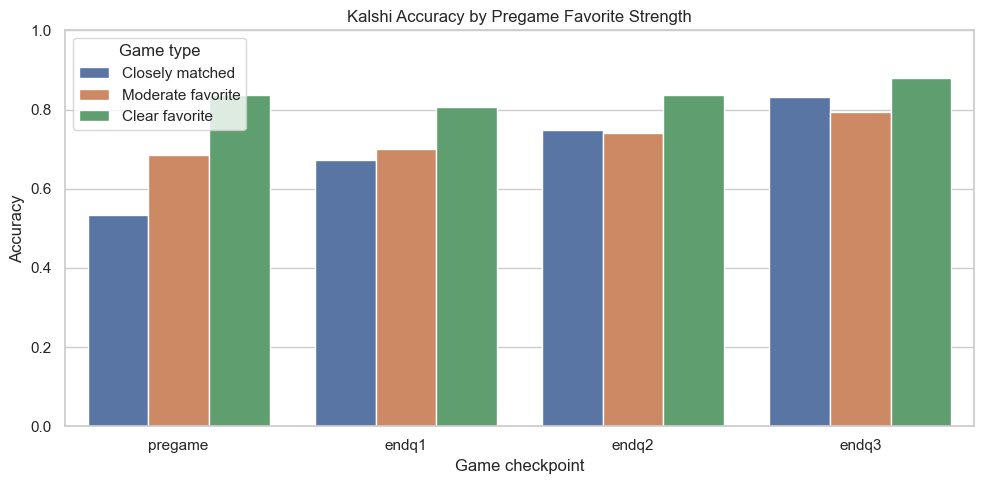

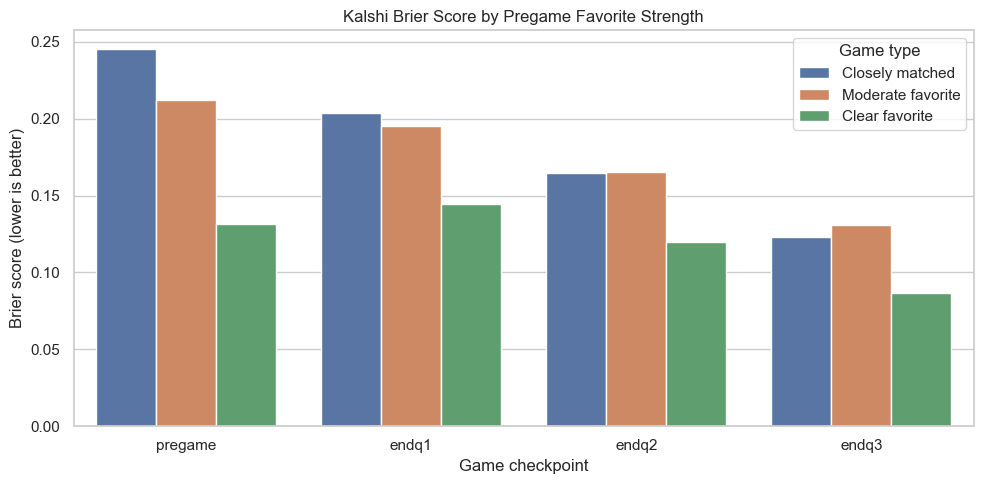

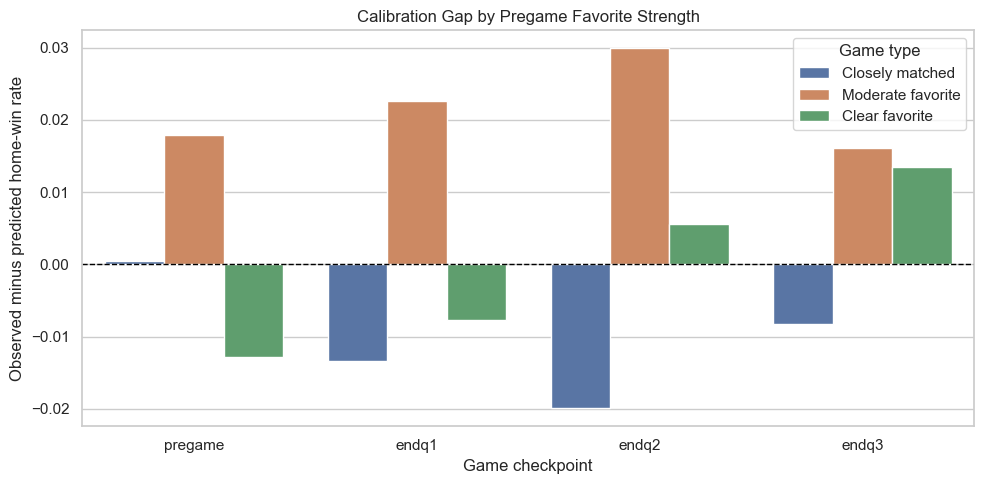

In [49]:
# Accuracy by game type and checkpoint.
plt.figure(figsize=(10, 5))

sns.barplot(
    data=favorite_results,
    x="checkpoint",
    y="accuracy",
    hue="favorite_group",
    errorbar=None
)

plt.title("Kalshi Accuracy by Pregame Favorite Strength")
plt.xlabel("Game checkpoint")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend(title="Game type")
plt.tight_layout()
plt.show()

# Brier score by game type and checkpoint.
plt.figure(figsize=(10, 5))

sns.barplot(
    data=favorite_results,
    x="checkpoint",
    y="brier_score",
    hue="favorite_group",
    errorbar=None
)

plt.title("Kalshi Brier Score by Pregame Favorite Strength")
plt.xlabel("Game checkpoint")
plt.ylabel("Brier score (lower is better)")
plt.legend(title="Game type")
plt.tight_layout()
plt.show()

# Calibration gap by game type and checkpoint.
plt.figure(figsize=(10, 5))

sns.barplot(
    data=favorite_results,
    x="checkpoint",
    y="calibration_gap",
    hue="favorite_group",
    errorbar=None
)

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Calibration Gap by Pregame Favorite Strength")
plt.xlabel("Game checkpoint")
plt.ylabel("Observed minus predicted home-win rate")
plt.legend(title="Game type")
plt.tight_layout()
plt.show()

**Probability Movement**

This cell measures the absolute change between each checkpoint’s Kalshi probability and the pregame probability, grouping games into low, moderate, and high probability movement categories. It then compares accuracy, Brier score, log loss, and calibration gap across these groups to investigate whether larger market probability changes are associated with differences in predictive performance.

In [51]:
movement_results = []

# Probability movement is measured relative to pregame.
pregame_p = prepared[
    ("pregame", "with_probability")
]["probability"].reset_index(drop=True)

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:

        key = (checkpoint, variant)

        y = prepared[key]["y"].reset_index(drop=True)
        p = prepared[key]["probability"].reset_index(drop=True)

        if not (len(y) == len(p) == len(pregame_p)):
            raise ValueError(
                f"Rows are not aligned for {key}; "
                "merge by game ID before calculating movement."
            )

        # Absolute movement in probability points, from 0 to 1.
        movement = (p - pregame_p).abs()

        # Movement is defined using the same checkpoint's market
        # probability, so pregame movement is zero by definition.
        movement_group = pd.cut(
            movement,
            bins=[-np.inf, 0.05, 0.15, np.inf],
            labels=[
                "Low movement",
                "Moderate movement",
                "High movement"
            ],
            right=False
        )

        evaluation = pd.DataFrame({
            "HOME_WIN": y,
            "PROBABILITY": p,
            "MOVEMENT_GROUP": movement_group
        })

        evaluation = evaluation.loc[
            evaluation["HOME_WIN"].isin([0, 1])
            & evaluation["PROBABILITY"].between(0, 1)
            & evaluation["MOVEMENT_GROUP"].notna()
        ].copy()

        evaluation["HOME_WIN"] = evaluation["HOME_WIN"].astype(int)

        for group_name, group in evaluation.groupby(
            "MOVEMENT_GROUP", observed=True
        ):
            actual = group["HOME_WIN"].to_numpy()
            prob = group["PROBABILITY"].to_numpy()

            movement_results.append({
                "checkpoint": checkpoint,
                "variant": variant,
                "movement_group": str(group_name),
                "n_games": len(group),
                "accuracy": accuracy_score(
                    actual, (prob >= 0.5).astype(int)
                ),
                "brier_score": brier_score_loss(actual, prob),
                "log_loss": log_loss(
                    actual, prob, labels=[0, 1]
                ),
                "calibration_gap": actual.mean() - prob.mean()
            })

movement_results = pd.DataFrame(movement_results)

print("PERFORMANCE BY PROBABILITY MOVEMENT")
display(
    movement_results.round(4).sort_values(
        ["checkpoint", "variant", "movement_group"]
    )
)

PERFORMANCE BY PROBABILITY MOVEMENT


,checkpoint,variant,movement_group,n_games,accuracy,brier_score,log_loss,calibration_gap
4,endq1,with_probability,High movement,416,0.7380,0.1799,0.5318,0.0074
2,endq1,with_probability,Low movement,311,0.7235,0.1788,0.5309,-0.0200
3,endq1,with_probability,Moderate movement,414,0.7319,0.1790,0.5301,0.0130
7,endq1,without_probability,High movement,416,0.7380,0.1799,0.5318,0.0074
5,endq1,without_probability,Low movement,311,0.7235,0.1788,0.5309,-0.0200
6,endq1,without_probability,Moderate movement,414,0.7319,0.1790,0.5301,0.0130
10,endq2,with_probability,High movement,601,0.7937,0.1396,0.4262,0.0146
8,endq2,with_probability,Low movement,192,0.7448,0.1619,0.4836,-0.0168
9,endq2,with_probability,Moderate movement,348,0.7672,0.1570,0.4782,0.0091
13,endq2,without_probability,High movement,601,0.7937,0.1396,0.4262,0.0146


**Results**

Kalshi’s accuracy generally increases with greater probability movement, with high-movement games reaching 85.98% accuracy by the end of the third quarter, compared with 74.80% for low-movement games. High-movement games also have lower Brier scores and log loss, suggesting more reliable predictions.

**13. Comparison by Checkpoint**

This cell identifies the highest- and lowest-accuracy favorite-strength groups at each game checkpoint by comparing accuracy across the pregame favorite categories. It reports each group’s probability variant and sample size to highlight which game types Kalshi predicts most and least accurately as the game progresses.

In [54]:
for checkpoint in CHECKPOINTS:

    subset = favorite_results.loc[
        favorite_results["checkpoint"] == checkpoint
    ]

    if subset.empty:
        continue

    best = subset.loc[subset["accuracy"].idxmax()]
    worst = subset.loc[subset["accuracy"].idxmin()]

    print(f"\n{checkpoint.upper()}")
    print(
        f"Highest accuracy: {best['favorite_group']} "
        f"({best['variant']}), "
        f"{best['accuracy']:.1%}, n={best['n_games']}"
    )
    print(
        f"Lowest accuracy: {worst['favorite_group']} "
        f"({worst['variant']}), "
        f"{worst['accuracy']:.1%}, n={worst['n_games']}"
    )


PREGAME
Highest accuracy: Clear favorite (with_probability), 83.7%, n=410
Lowest accuracy: Closely matched (with_probability), 53.4%, n=309

ENDQ1
Highest accuracy: Clear favorite (with_probability), 80.7%, n=410
Lowest accuracy: Closely matched (with_probability), 67.3%, n=309

ENDQ2
Highest accuracy: Clear favorite (with_probability), 83.7%, n=410
Lowest accuracy: Moderate favorite (with_probability), 74.2%, n=422

ENDQ3
Highest accuracy: Clear favorite (with_probability), 88.0%, n=410
Lowest accuracy: Moderate favorite (with_probability), 79.4%, n=422


**Results**

Clear favorites achieve the highest accuracy at every checkpoint, ranging from 80.7% at the end of the first quarter to 88.0% at the end of the third quarter. Closely matched games have the lowest pregame and first-quarter accuracy (53.4% and 67.3%), while moderate-favorite games have the lowest accuracy in the second and third quarters (74.2% and 79.4%).

**Consolidated Visualizations**

The following 3 visualizations are the silhouette chart, heatmap data, and pca for k means clustering. In the code above, they are seperated by checkpoint. In the below visualizations, they are combined for ease of viewing.  

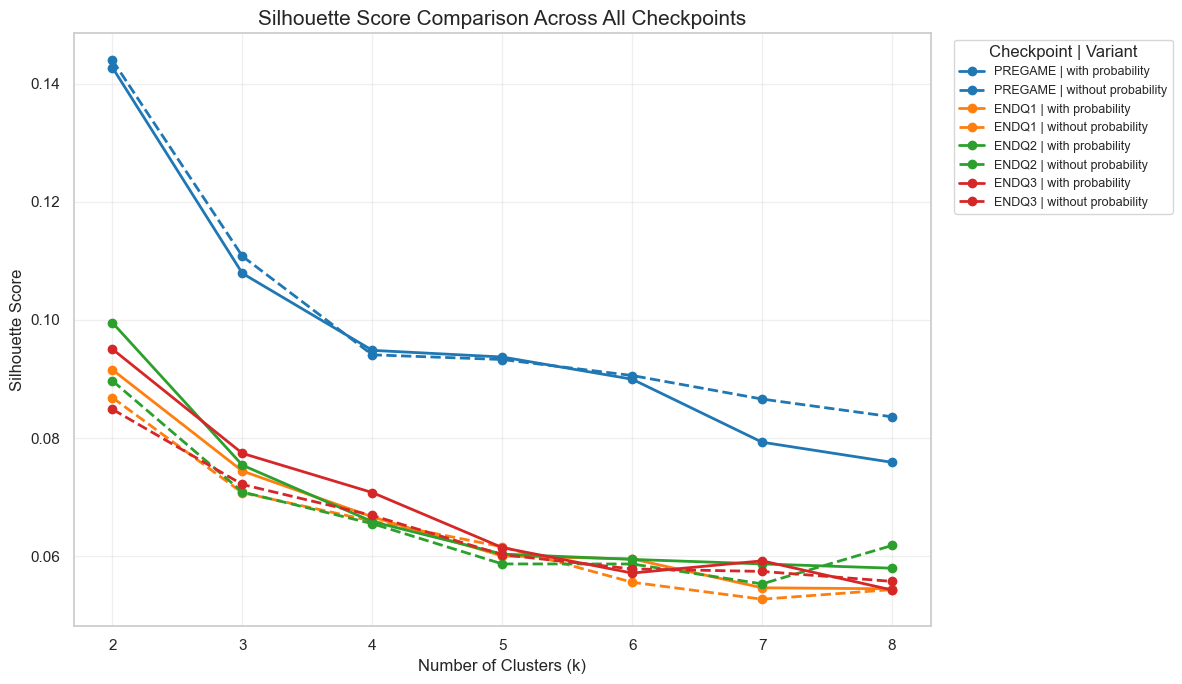

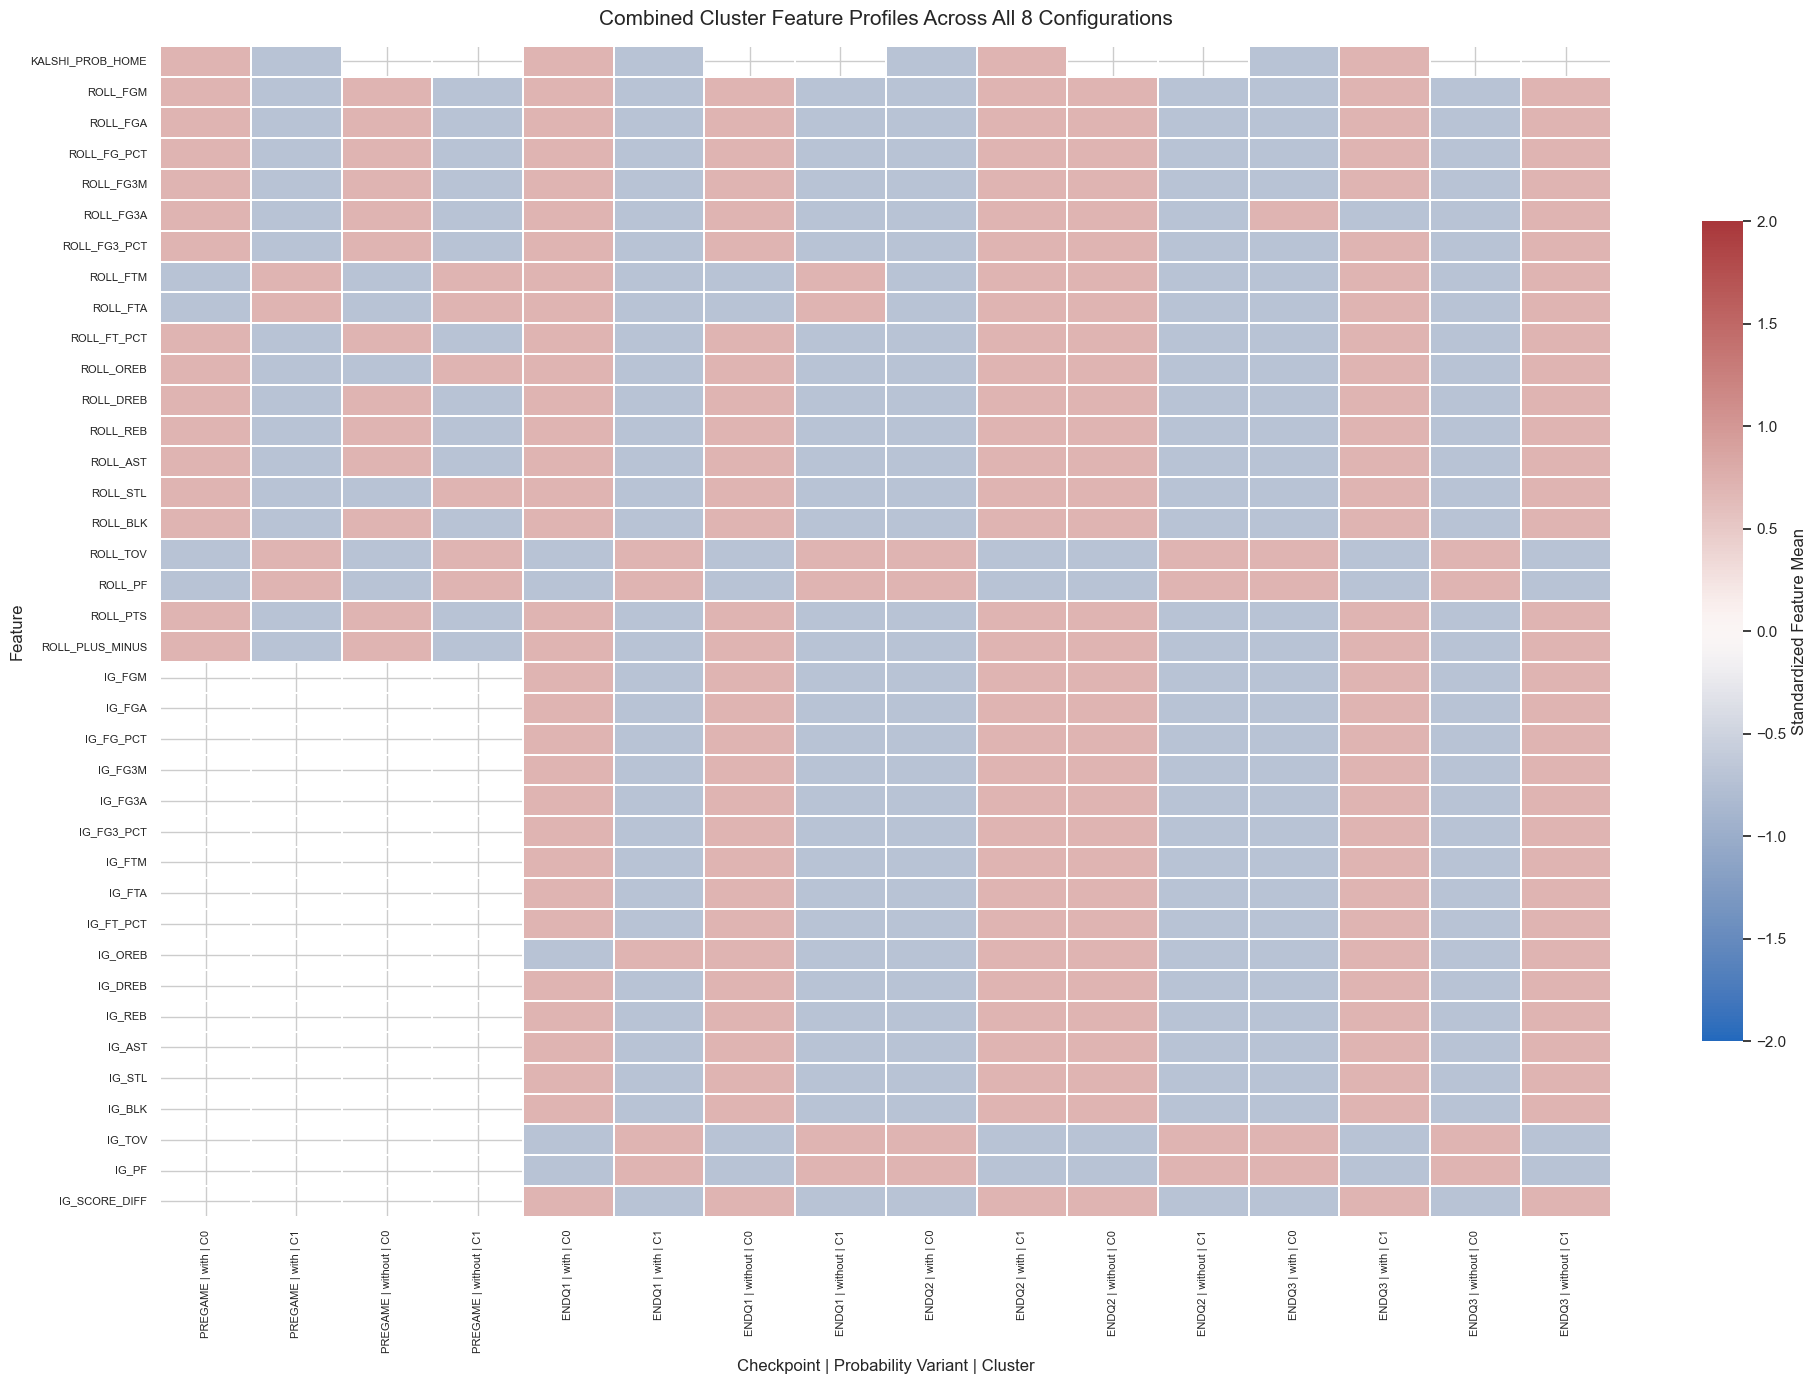

In [57]:
#  ONE SILHOUETTE CHART WITH ALL 8 LINES

fig, ax = plt.subplots(figsize=(12, 7))

colors = sns.color_palette("tab10", n_colors=len(CHECKPOINTS))
linestyles = {
    "with_probability": "-",
    "without_probability": "--"
}

for i, checkpoint in enumerate(CHECKPOINTS):
    for variant in VARIANTS:
        key = (checkpoint, variant)
        scores = validation_by_key[key].sort_values("k")

        ax.plot(
            scores["k"],
            scores["silhouette"],
            marker="o",
            linewidth=2,
            color=colors[i],
            linestyle=linestyles[variant],
            label=(
                f"{checkpoint.upper()} | "
                f"{variant.replace('_', ' ')}"
            )
        )

ax.set_title(
    "Silhouette Score Comparison Across All Checkpoints",
    fontsize=15
)
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(list(K_VALUES))
ax.grid(True, alpha=0.3)
ax.legend(
    title="Checkpoint | Variant",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()


# ONE HEATMAP CONTAINING ALL 8 CONFIGURATIONS

heatmap_blocks = []

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:
        key = (checkpoint, variant)
        profile = profile_by_key[key].copy()

        # Standardize feature means across clusters within
        # each checkpoint/variant, matching the original approach.
        std = profile.std(axis=0).replace(0, 1)

        standardized = (
            profile - profile.mean(axis=0)
        ).div(std, axis=1)

        # Transpose so features are rows and clusters are columns.
        block = standardized.T

        # Label each cluster with its checkpoint and variant.
        block.columns = [
            f"{checkpoint.upper()} | "
            f"{variant.replace('_probability', '').replace('_', ' ')} "
            f"| C{cluster}"
            for cluster in profile.index
        ]

        heatmap_blocks.append(block)

# Align all feature names and combine every configuration.
combined_heatmap = pd.concat(
    heatmap_blocks,
    axis=1
)

# One heatmap for every checkpoint, variant, and cluster.
fig, ax = plt.subplots(
    figsize=(max(20, combined_heatmap.shape[1] * 0.45), 14)
)

sns.heatmap(
    combined_heatmap,
    cmap="vlag",
    center=0,
    vmin=-2,
    vmax=2,
    mask=combined_heatmap.isna(),
    linewidths=0.15,
    linecolor="white",
    cbar_kws={
        "label": "Standardized Feature Mean",
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Combined Cluster Feature Profiles Across All 8 Configurations",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Checkpoint | Probability Variant | Cluster")
ax.set_ylabel("Feature")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

PREGAME | with_probability | Variance explained: 38.2%
PREGAME | without_probability | Variance explained: 38.6%
ENDQ1 | with_probability | Variance explained: 26.5%
ENDQ1 | without_probability | Variance explained: 25.6%
ENDQ2 | with_probability | Variance explained: 27.8%
ENDQ2 | without_probability | Variance explained: 26.4%
ENDQ3 | with_probability | Variance explained: 27.8%
ENDQ3 | without_probability | Variance explained: 26.5%


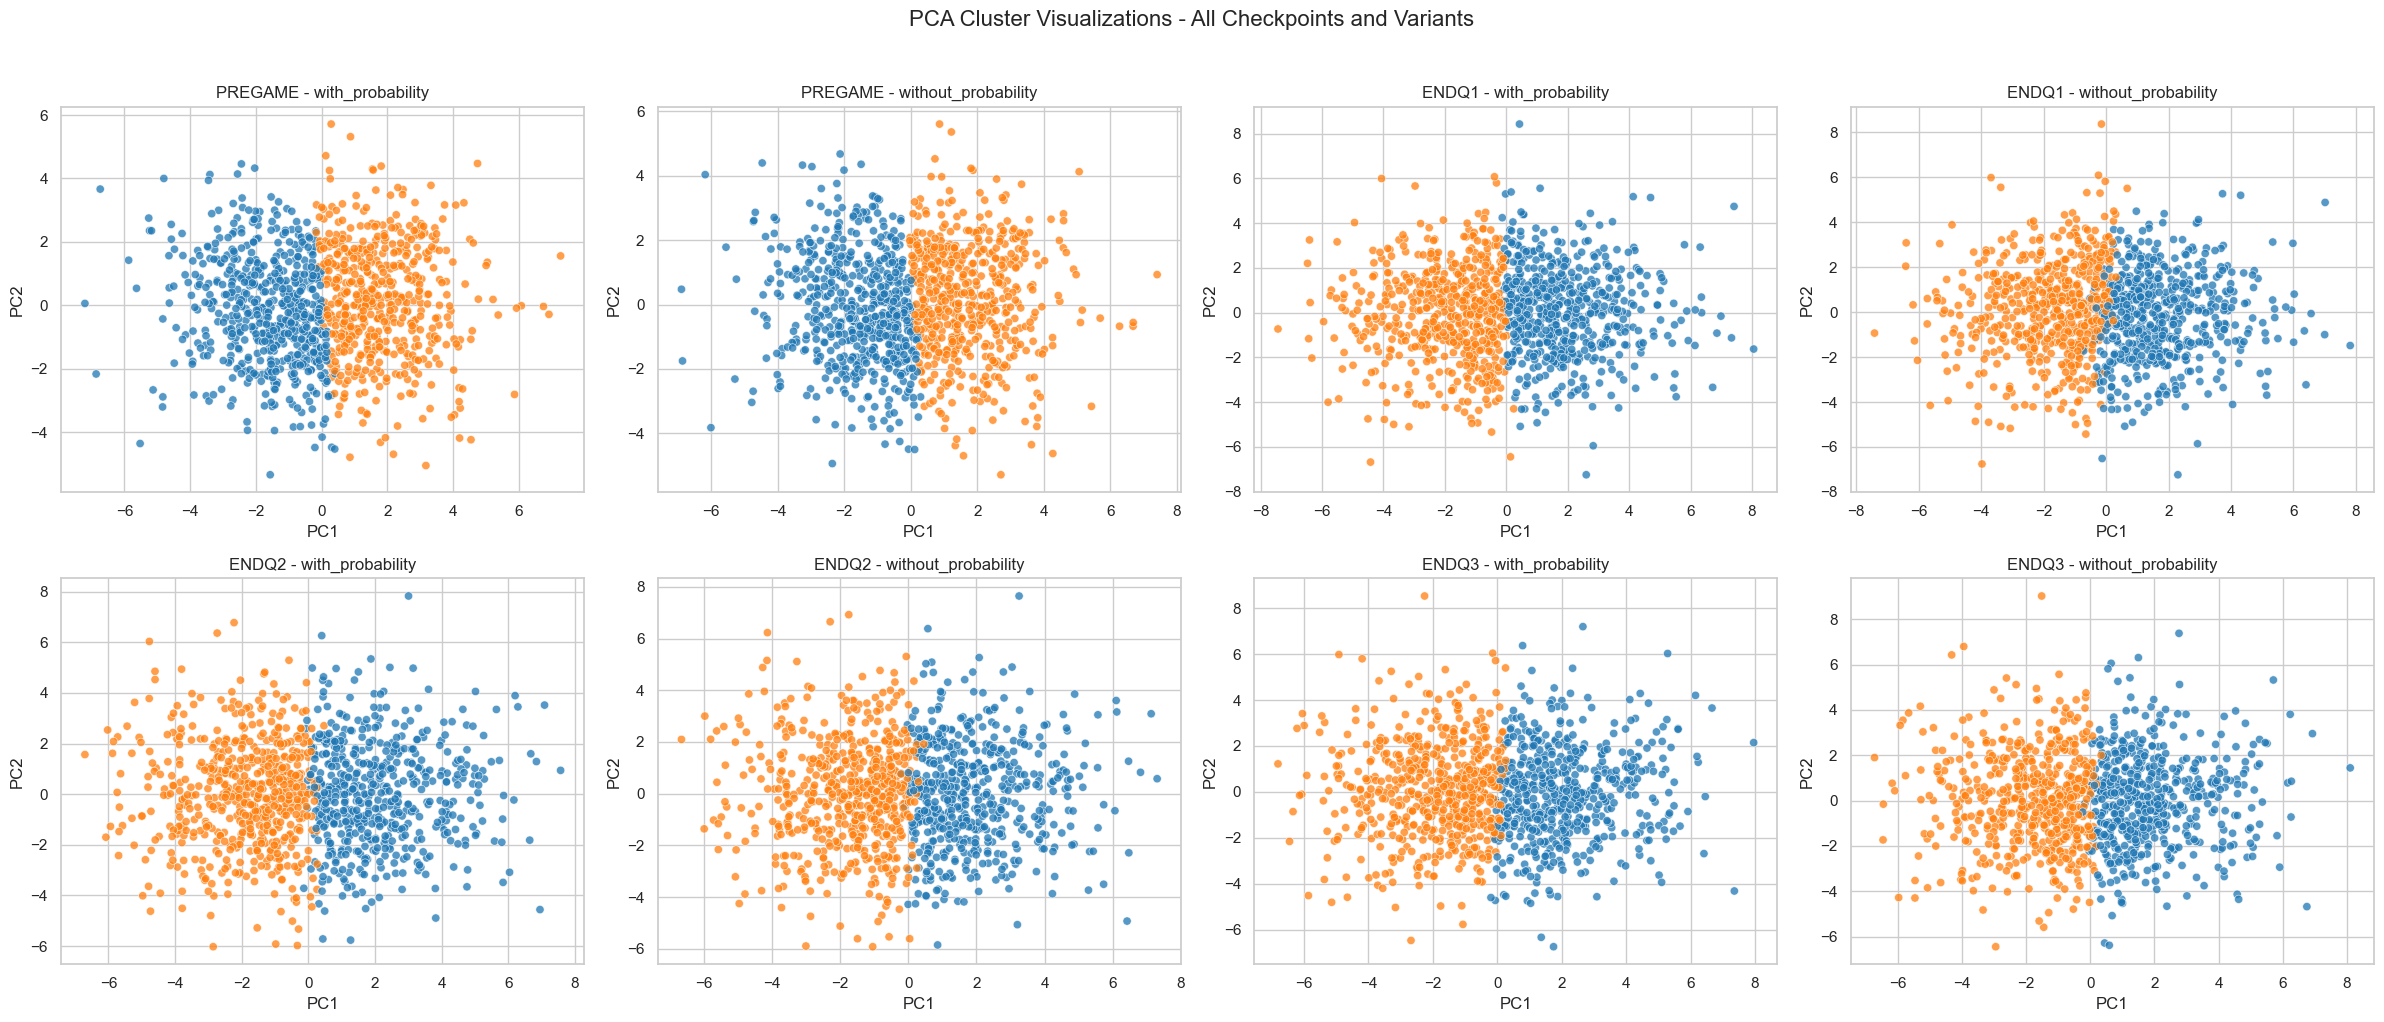

In [58]:
n_plots = len(CHECKPOINTS) * len(VARIANTS)
n_cols = 4
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(6 * n_cols, 5 * n_rows)
)

axes = axes.flatten()

plot_idx = 0

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:
        key = (checkpoint, variant)

        X = prepared[key]["X"]
        clusters = models[key]["clusters"]

        pca = PCA(n_components=2)
        components = pca.fit_transform(X)

        pca_df = pd.DataFrame({
            "PC1": components[:, 0],
            "PC2": components[:, 1],
            "Cluster": clusters.astype(str)
        })

        ax = axes[plot_idx]

        sns.scatterplot(
            data=pca_df,
            x="PC1",
            y="PC2",
            hue="Cluster",
            palette="tab10",
            alpha=0.75,
            legend=False,
            ax=ax
        )

        ax.set_title(f"{checkpoint.upper()} - {variant}")
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")

        print(
            f"{checkpoint.upper()} | {variant} | "
            f"Variance explained: "
            f"{pca.explained_variance_ratio_.sum():.1%}"
        )

        models[key]["pca"] = pca
        plot_idx += 1

# Hide any unused subplot areas
for j in range(plot_idx, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "PCA Cluster Visualizations - All Checkpoints and Variants",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

**Hierarchical Clustering Visualizations**

The below 2 visuals are showing the heirarchical clustering perspective. Included are scatterplots for the 2 principal components, and a heatmap across all configurations.

Hierarchical clustering completed for all configurations.
Hierarchical PCA | PREGAME | with_probability: 38.2% variance explained
Hierarchical PCA | PREGAME | without_probability: 38.6% variance explained
Hierarchical PCA | ENDQ1 | with_probability: 26.5% variance explained
Hierarchical PCA | ENDQ1 | without_probability: 25.6% variance explained
Hierarchical PCA | ENDQ2 | with_probability: 27.8% variance explained
Hierarchical PCA | ENDQ2 | without_probability: 26.4% variance explained
Hierarchical PCA | ENDQ3 | with_probability: 27.8% variance explained
Hierarchical PCA | ENDQ3 | without_probability: 26.5% variance explained


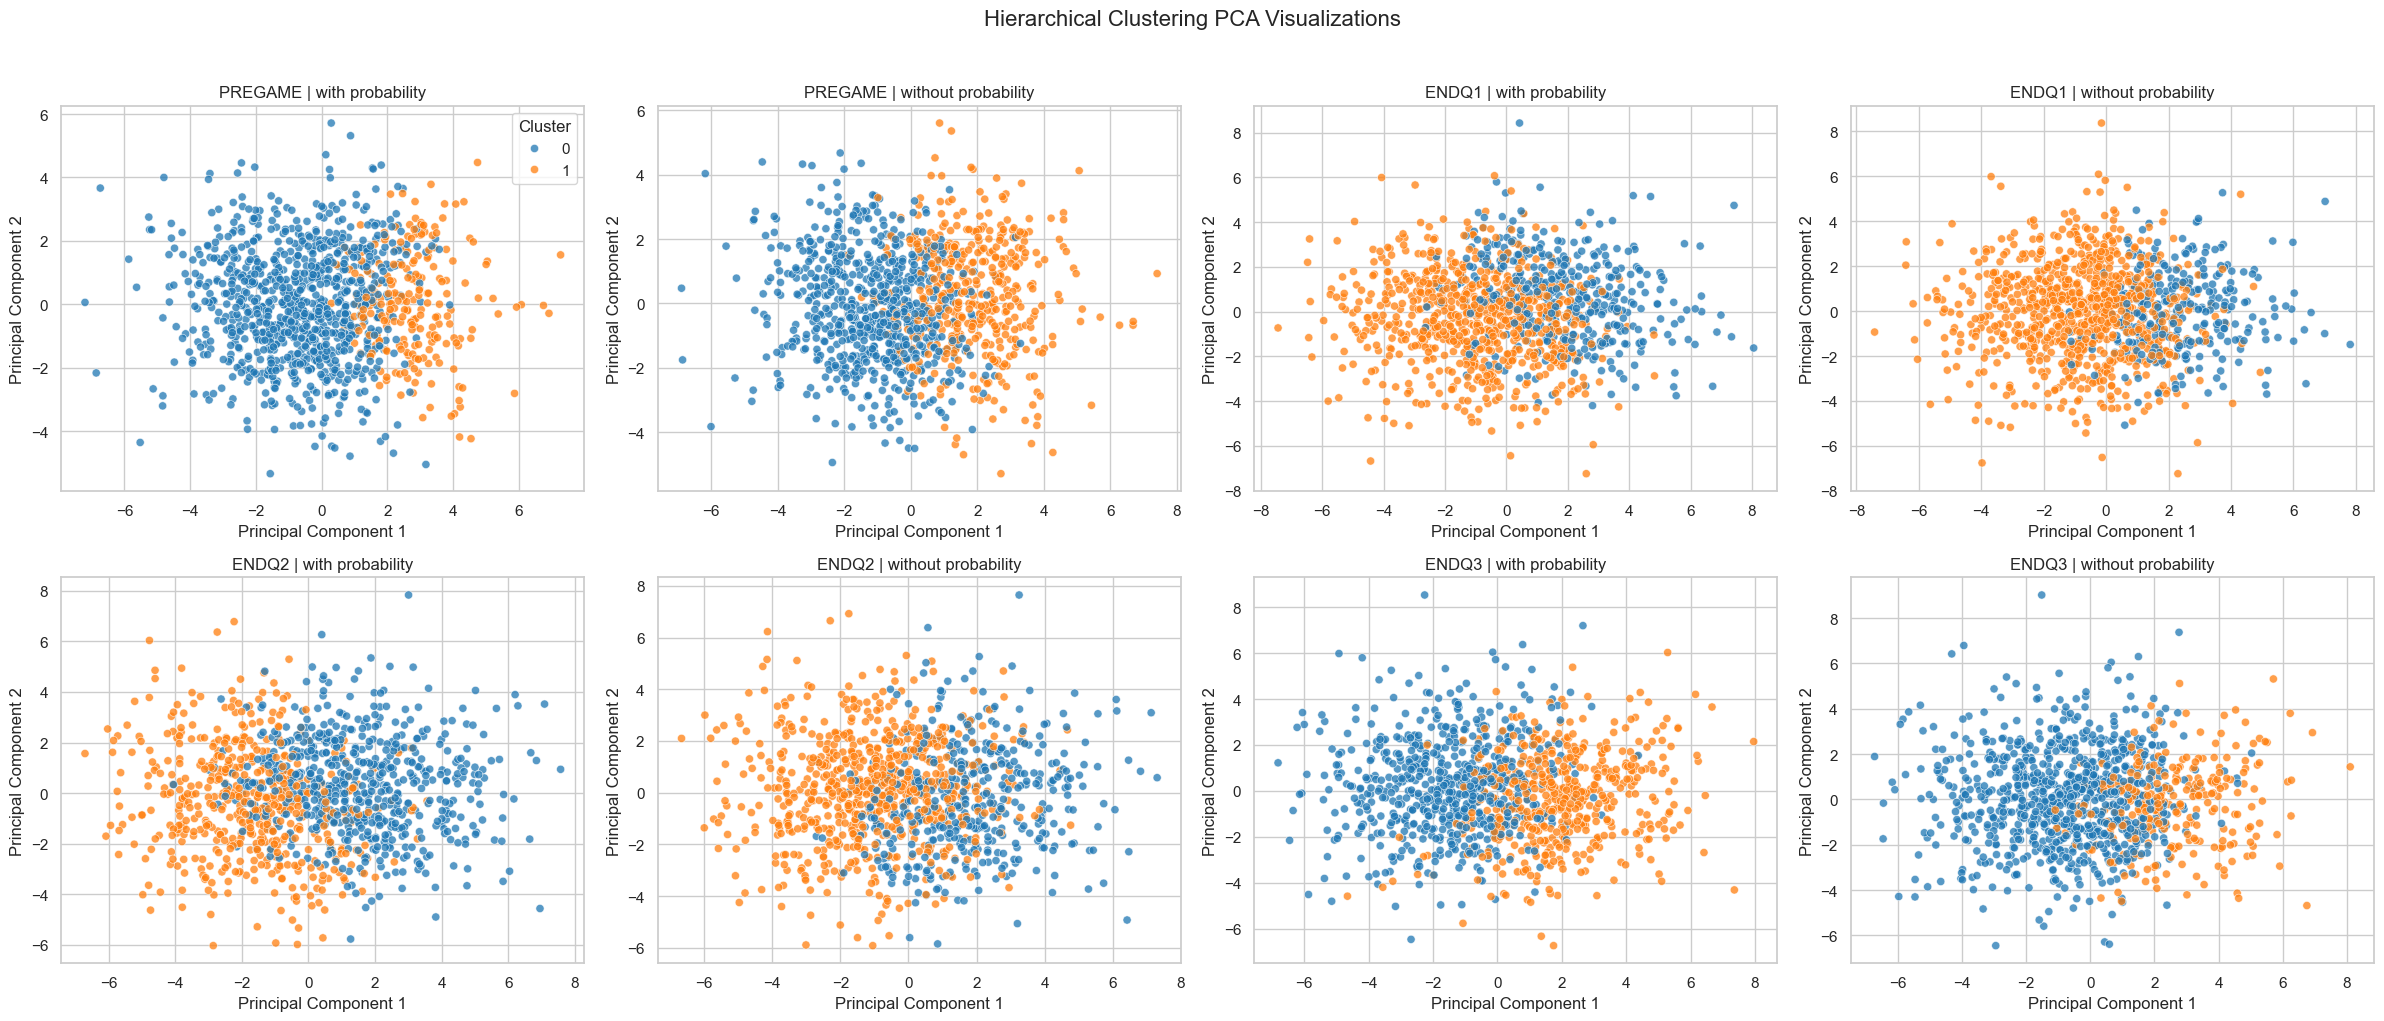

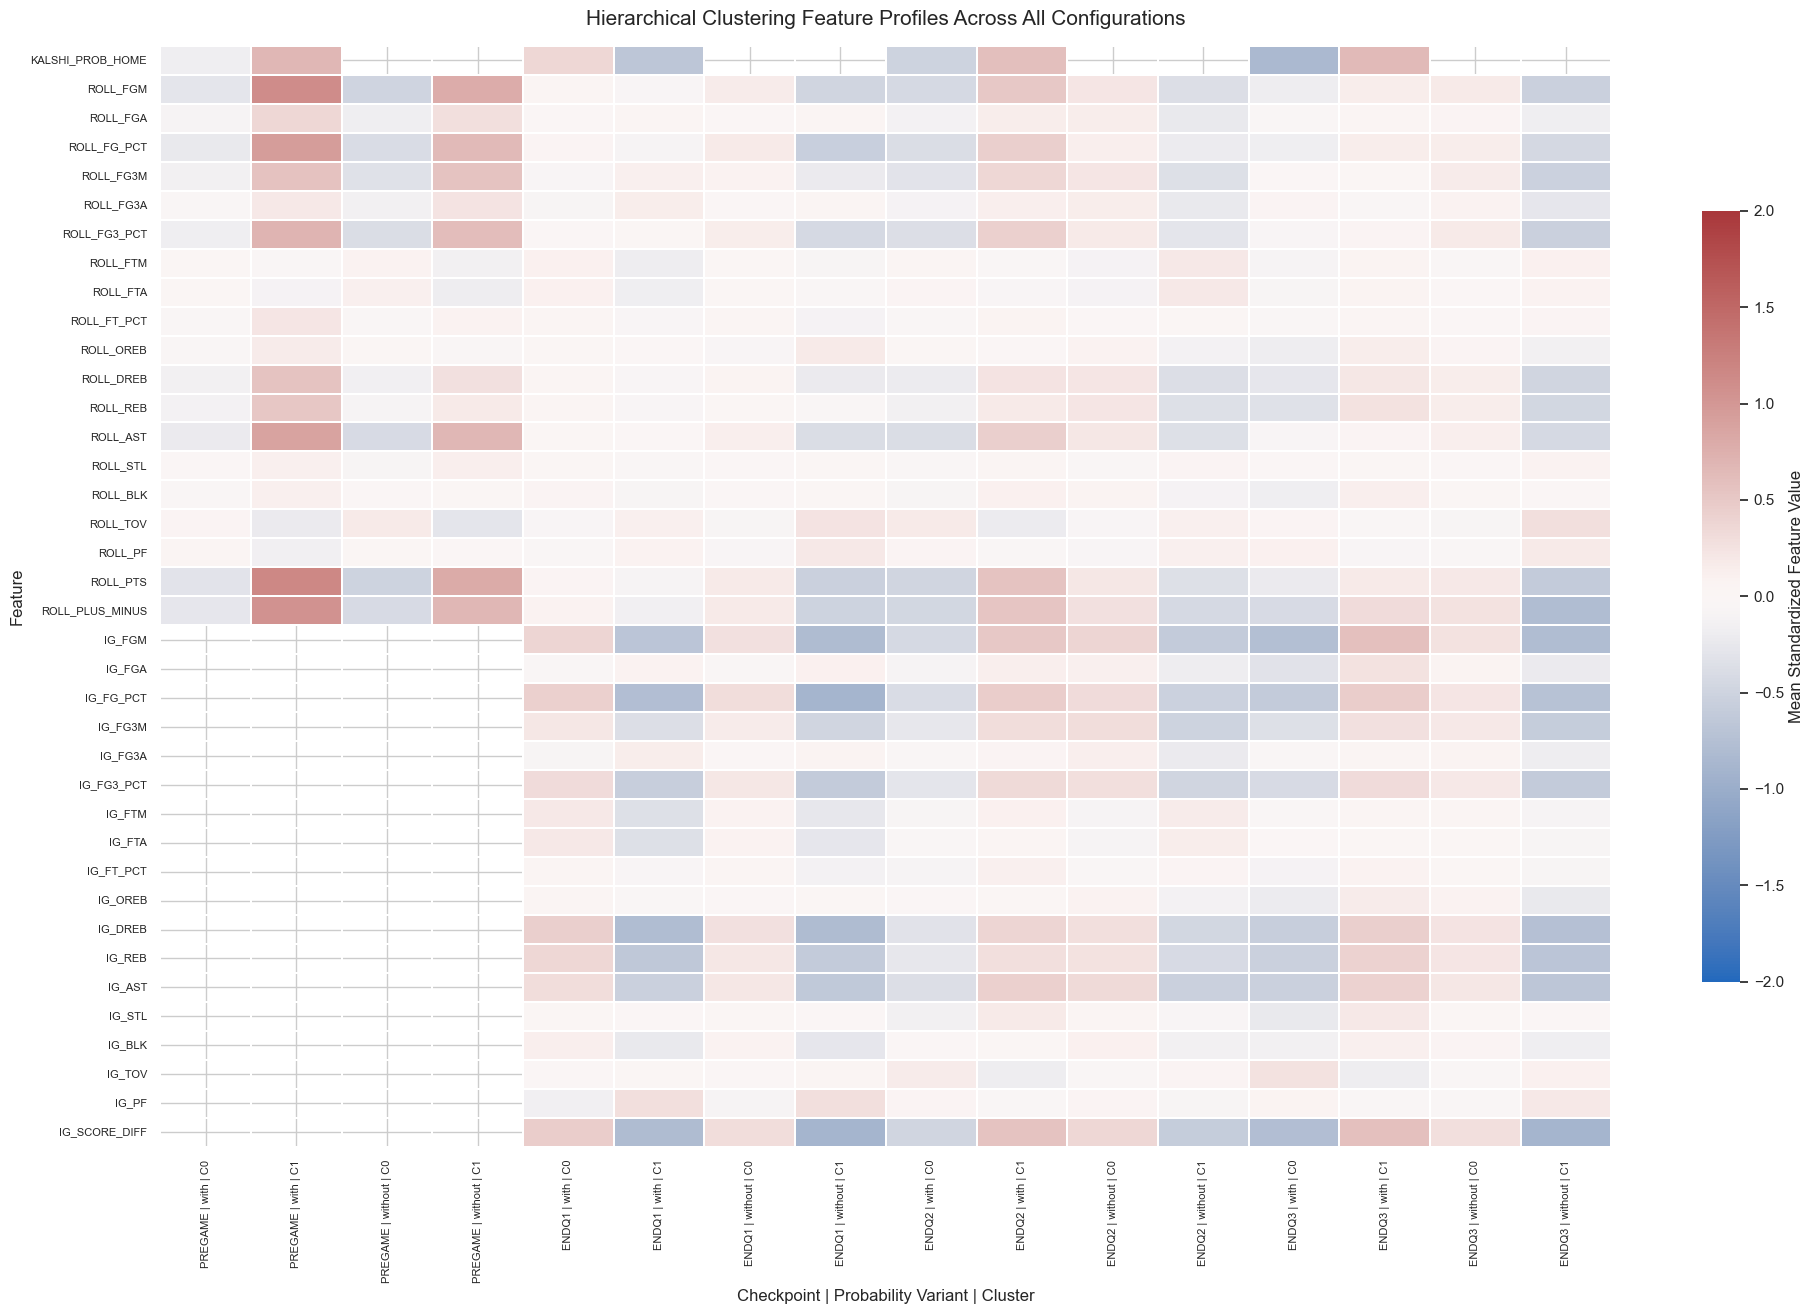

In [60]:
# Store hierarchical clustering results separately from K-means.
hierarchical_models = {}
hierarchical_profiles = {}

# Fit hierarchical clustering for every checkpoint and variant

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:
        key = (checkpoint, variant)

        # Use the same prepared feature matrix as K-means.
        X = prepared[key]["X"]
        X_array = np.asarray(X)

        # Use the same number of clusters selected for K-means.
        k = len(np.unique(models[key]["clusters"]))

        # Fit agglomerative hierarchical clustering.
        hierarchical = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        labels = hierarchical.fit_predict(X_array)

        hierarchical_models[key] = {
            "model": hierarchical,
            "clusters": labels
        }

        # Recover feature names when available.
        if isinstance(X, pd.DataFrame):
            feature_names = list(X.columns)
        else:
            feature_names = None

            for name in [
                "feature_names",
                "feature_cols",
                "feature_columns",
                "features",
                "columns"
            ]:
                candidate = prepared[key].get(name)

                if candidate is not None:
                    candidate = list(candidate)

                    if (
                        len(candidate) == X_array.shape[1]
                        and all(isinstance(c, str) for c in candidate)
                    ):
                        feature_names = candidate
                        break

            if feature_names is None:
                feature_names = [
                    f"Feature {i + 1}"
                    for i in range(X_array.shape[1])
                ]

        # Calculate mean feature values within each cluster.
        profile = pd.DataFrame(
            X_array,
            columns=feature_names
        )
        profile["Cluster"] = labels

        cluster_profile = profile.groupby("Cluster").mean()

        hierarchical_profiles[key] = cluster_profile

print("Hierarchical clustering completed for all configurations.")


# HIERARCHICAL CLUSTERING PCA VISUALIZATIONS

n_plots = len(CHECKPOINTS) * len(VARIANTS)
n_cols = 4
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(6 * n_cols, 5 * n_rows)
)

axes = np.asarray(axes).flatten()

plot_idx = 0

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:
        key = (checkpoint, variant)

        X = prepared[key]["X"]
        labels = hierarchical_models[key]["clusters"]

        # Project the same features into two PCA dimensions.
        pca = PCA(n_components=2)
        components = pca.fit_transform(X)

        pca_df = pd.DataFrame({
            "PC1": components[:, 0],
            "PC2": components[:, 1],
            "Cluster": labels.astype(str)
        })

        ax = axes[plot_idx]

        sns.scatterplot(
            data=pca_df,
            x="PC1",
            y="PC2",
            hue="Cluster",
            palette="tab10",
            alpha=0.75,
            s=35,
            legend=(plot_idx == 0),
            ax=ax
        )

        ax.set_title(
            f"{checkpoint.upper()} | "
            f"{variant.replace('_', ' ')}"
        )
        ax.set_xlabel("Principal Component 1")
        ax.set_ylabel("Principal Component 2")

        print(
            f"Hierarchical PCA | {checkpoint.upper()} | {variant}: "
            f"{pca.explained_variance_ratio_.sum():.1%} "
            "variance explained"
        )

        plot_idx += 1

# Hide unused subplot areas.
for j in range(plot_idx, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Hierarchical Clustering PCA Visualizations",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


# HIERARCHICAL CLUSTER FEATURE-PROFILE HEATMAP

heatmap_blocks = []

for checkpoint in CHECKPOINTS:
    for variant in VARIANTS:
        key = (checkpoint, variant)

        profile = hierarchical_profiles[key].copy()

        # Plot the cluster means directly.
        block = profile.T

        # Identify checkpoint, feature variant, and cluster.
        block.columns = [
            f"{checkpoint.upper()} | "
            f"{variant.replace('_probability', '').replace('_', ' ')} "
            f"| C{cluster}"
            for cluster in profile.index
        ]

        heatmap_blocks.append(block)

# Combine feature profiles from all eight configurations.
combined_hierarchical_heatmap = pd.concat(
    heatmap_blocks,
    axis=1
)

fig, ax = plt.subplots(
    figsize=(
        max(20, combined_hierarchical_heatmap.shape[1] * 0.55),
        max(10, combined_hierarchical_heatmap.shape[0] * 0.35)
    )
)

sns.heatmap(
    combined_hierarchical_heatmap,
    cmap="vlag",
    center=0,
    vmin=-2,
    vmax=2,
    mask=combined_hierarchical_heatmap.isna(),
    linewidths=0.15,
    linecolor="white",
    cbar_kws={
        "label": "Mean Standardized Feature Value",
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Hierarchical Clustering Feature Profiles Across All Configurations",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Checkpoint | Probability Variant | Cluster")
ax.set_ylabel("Feature")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()